# Week 3 · Classical Econometrics
### FinTech & AI Engineering — MSc Banking & Finance

---

## 🧭 Where we are in the build

Week 1 taught you to *look* at financial data; Week 2 taught you to *distrust* it and clean it under a rulebook. This week we **model** for the first time: what moves an asset's return, how sure we can be, and — the part most people skip — whether the number we just printed deserves to be believed.

The tool is the most important one in empirical finance: **linear regression**. Every beta on a screen, every "alpha" a fund manager claims, every factor exposure in a risk report is a regression coefficient. In the product you are building, this week's work becomes the **Analyst Agent's first skill**, and the governance instrument it feeds is the one Week 2 promised: the eval rules gain **statistical teeth**.

> **The week's centerpiece is the OLS trial.** A regression is not a result; it is a *defendant*. We estimate it, test the right hypothesis, cross-examine its residuals, replace its standard errors when they are wrong, check whether its beta even held still, and — before any of that — check that the regression was legal to run. Only a model that survives the trial gets reported.

> **Human first, agent second.** An agent will happily print `p = 0.003` next to any coefficient. This week you learn what that number assumes and when it lies.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

1. Estimate a regression **by hand** and with `statsmodels`, and read a regression summary line by line.
2. Test the hypotheses that matter in finance ($\beta = 1$, $\alpha = 0$) and say what a $p$-value does *not* mean.
3. Estimate the **CAPM** and a **three-factor model** on real assets and interpret loadings and alpha.
4. Run four **diagnostic tests** and explain which failures bias coefficients and which only break standard errors.
5. Repair inference with **Newey–West (HAC)** standard errors.
6. Test **parameter stability** (rolling betas, Chow test) — beta is a process, not a number.
7. Recognize the **spurious-regression trap**, apply the **ADF** guard, and encode all of it as the Analyst Agent's **eval rules**.

## 🗺️ How to use this notebook

Run cells top to bottom (`Shift+Enter`). Markdown carries the theory, code carries the practice, every step is commented. The notebook extends **last week's `data/` folder** with a few more tickers; without files or internet it falls back to a synthetic market, so it always runs. The last cell is the raw material for this week's assignment.

---
# 1 · Why regression is the language of finance

Most quantitative statements in finance are of the form *"given this, we expect that"*: given the market moved 1%, what do we expect this stock to do? Regression is the workhorse for such statements because it is transparent — every coefficient means something — and *auditable*: it comes with a standard error, and the standard error comes with assumptions you can test.

| Financial object | …is this regression coefficient |
|---|---|
| **Beta** of a stock | slope of its excess return on the market's excess return |
| **Alpha** | the intercept of that regression, annualized |
| **Factor exposures** in a risk report | slopes on size and value factors |
| **Hedge ratio** | slope of one asset's return on another's |

The catch — and the reason this week exists — is that classical regression theory assumes tidy errors, while financial returns have **fat tails and volatility clustering** (Week 1). The coefficients survive that mismatch; the *standard errors* usually do not.

## This week's additions to the toolkit

| Library | What it adds |
|---|---|
| **`statsmodels`** | `OLS`, the summary table, diagnostic tests, HAC standard errors, the ADF test |
| **`scipy.stats`** | the $t$ and $F$ distributions behind every $p$-value |

```bash
pip install pandas numpy matplotlib scipy statsmodels yfinance
```

In [1]:
# ============================================================
# Cell 1 — Imports and environment check
# ============================================================
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats                                   # t and F distributions

import statsmodels
import statsmodels.api as sm                              # sm.OLS, sm.add_constant, sm.qqplot
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox   # heteroskedasticity, autocorrelation
from statsmodels.stats.stattools import jarque_bera       # normality
from statsmodels.tsa.stattools import adfuller            # unit-root test (the spurious-regression guard)

pd.set_option("display.width", 130)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)

RNG = np.random.default_rng(seed=42)      # reproducibility for the synthetic fallback and simulations

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("statsmodels :", statsmodels.__version__)
print("✅ Environment ready.")

Python      : 3.14.5
pandas      : 3.0.3
statsmodels : 0.14.6
✅ Environment ready.


---
# 2 · Getting the data — the trio grows a small factor universe

We keep **SPY** and **BTC** from Weeks 1–2 and add exactly what a factor regression needs: a risk-free rate, two more factor proxies, and three stocks with different personalities.

| Group | Ticker(s) | Role |
|---|---|---|
| Risk-free rate | `^IRX` | 13-week US T-bill yield (in %) — the $R_f$ every excess return subtracts |
| Market factor | `SPY` | **MKT** = SPY − $R_f$ |
| Size factor | `IWM` (Russell 2000) | **SMB** ≈ IWM − SPY (small minus big) |
| Value factor | `IWD`, `IWF` (Russell 1000 Value / Growth) | **HML** ≈ IWD − IWF (value minus growth) |
| Test assets | `AAPL` (growth), `JPM` (value/financial), `KO` (defensive) | three stocks that should load differently |
| Outsiders | `GLD` (gold), `BTC-USD` | what does an *equity* model say about non-equities? |

**A word of honesty.** The real Fama–French factors are built from sorted portfolios of the whole US market. Our ETF spreads are **proxies** — tradable, daily, free, and close enough to learn how factor regressions work.

**Data path:** (1) files already in `data/`; (2) the download cell refreshes them via `yfinance` (needs internet); (3) neither → a **synthetic market** with known true betas, volatility clustering, fat tails and a built-in regime change in Bitcoin — so every regression below still has something real to find.

In [2]:
# ============================================================
# Cell 2 — Download via yfinance, defensively (one batch call)
# ============================================================
from pathlib import Path

import pandas as pd

Path("data").mkdir(exist_ok=True)

START = pd.Timestamp("2017-05-29")
# ETH's first Yahoo date — the binding asset since Week 1

TICKERS = {
    "irx": "^IRX",          # 13-week Treasury bill proxy
    "spy": "SPY",
    "iwm": "IWM",
    "iwd": "IWD",
    "iwf": "IWF",
    "aapl": "AAPL",
    "jpm": "JPM",
    "ko": "KO",
    "gld": "GLD",
    "btc": "BTC-USD",
    "eth": "ETH-USD",
    "aetf": "AETF.AT",
    "eurusd": "EURUSD=X"    
}

try:
    import yfinance as yf
    import logging

    # Keep yfinance quiet if an individual ticker fails.
    logging.getLogger("yfinance").setLevel(logging.CRITICAL)

    symbols = list(TICKERS.values())

    raw_dl = yf.download(
        symbols,
        start=START,
        auto_adjust=True,
        progress=False,
        group_by="column",
        threads=True,
    )

    if raw_dl is None or raw_dl.empty:
        raise RuntimeError("empty download")

    # --------------------------------------------------------
    # Handle both:
    #   MultiIndex columns: ("Close", "AAPL"), ...
    #   Flat columns:       "AAPL", ...
    # --------------------------------------------------------
    if isinstance(raw_dl.columns, pd.MultiIndex):
        if "Close" not in raw_dl.columns.get_level_values(0):
            raise RuntimeError("download contains no Close prices")

        close = raw_dl["Close"].copy()

    else:
        # Single-ticker downloads can occasionally return
        # ordinary columns rather than a MultiIndex.
        if "Close" in raw_dl.columns:
            close = raw_dl[["Close"]].copy()
            close.columns = [symbols[0]]
        else:
            close = raw_dl.copy()

    # Ensure a DatetimeIndex and remove timezone information.
    close.index = pd.to_datetime(close.index)

    if getattr(close.index, "tz", None) is not None:
        close.index = close.index.tz_localize(None)

    close = close.sort_index()

    # --------------------------------------------------------
    # Save each ticker on its own trading calendar.
    # Missing/failed tickers do not kill the entire download.
    # --------------------------------------------------------
    for stem, sym in TICKERS.items():

        if sym not in close.columns:
            print(f"⚠️  {stem} ({sym}): ticker missing from download")
            continue

        s = pd.to_numeric(close[sym], errors="coerce").dropna()
        s = s[~s.index.duplicated(keep="last")]

        if len(s) < 250:
            print(
                f"⚠️  {stem} ({sym}): only {len(s):,} rows, not saved"
            )
            continue

        s.rename("Close").to_frame().to_csv(
            f"data/{stem}.csv",
            index=True,
        )

        print(f"✅ {stem} ({sym}): {len(s):,} rows saved")

except Exception as e:
    print(
        f"⚠️  Download unavailable "
        f"({type(e).__name__}: {e}). "
        "Will use existing files in data/ or the synthetic fallback."
    )


✅ irx (^IRX): 2,348 rows saved
✅ spy (SPY): 2,348 rows saved
✅ iwm (IWM): 2,348 rows saved
✅ iwd (IWD): 2,348 rows saved
✅ iwf (IWF): 2,348 rows saved
✅ aapl (AAPL): 2,348 rows saved
✅ jpm (JPM): 2,348 rows saved
✅ ko (KO): 2,348 rows saved
✅ gld (GLD): 2,348 rows saved
✅ btc (BTC-USD): 3,413 rows saved
✅ eth (ETH-USD): 3,249 rows saved
✅ aetf (AETF.AT): 2,321 rows saved
✅ eurusd (EURUSD=X): 2,431 rows saved


In [3]:
# ============================================================
# Cell 3 — Loader + synthetic fallback
# ============================================================
# The fallback is all-or-nothing: either the whole universe is real, or the whole
# universe is one synthetic market whose true betas we KNOW — handy when learning
# what a regression can and cannot recover.

DATA_DIR = Path("data")
END_SYN  = pd.Timestamp("2026-09-18")        # fixed end date for the synthetic world
BREAK    = pd.Timestamp("2020-03-11")        # WHO pandemic declaration — the break date we test in §8

def load_price_file(stem: str) -> pd.Series | None:
    '''Week-2 loader: Close series from data/{stem}.csv; None if absent or broken.'''
    f = DATA_DIR / f"{stem}.csv"
    if not f.exists():
        return None
    df = pd.read_csv(f); df.columns = [str(c).strip() for c in df.columns]
    date_col = next((c for c in df.columns if c.lower().startswith("date")), df.columns[0])
    px_col   = next((c for c in df.columns if c.lower() in ("close", "adj close", "adj_close")), None)
    if px_col is None:
        return None
    s = pd.Series(pd.to_numeric(df[px_col], errors="coerce").values, index=pd.to_datetime(df[date_col], errors="coerce"))
    s = s[s.index.notna()].sort_index().dropna()
    return s if len(s) > 250 else None

def garch_path(n, sig, alpha=0.07, beta=0.90, df=5):
    '''Zero-mean shocks with volatility clustering (GARCH) and fat tails (Student-t): Week 1's stylized facts.'''
    omega = sig**2 * (1 - alpha - beta)
    z = RNG.standard_t(df, n) / np.sqrt(df / (df - 2))
    s2, r = np.empty(n), np.empty(n); s2[0] = sig**2
    for t in range(n):
        if t: s2[t] = omega + alpha * r[t-1]**2 + beta * s2[t-1]
        r[t] = np.sqrt(s2[t]) * z[t]
    return r

def generate_synthetic_market():
    bdays, alldays = pd.date_range(START, END_SYN, freq="B"), pd.date_range(START, END_SYN, freq="D")
    nb, rf = len(bdays), 0.02 / 252
    centred = lambda x, m: m + (x - x.mean())
    mkt = centred(garch_path(nb, 0.18/np.sqrt(252), df=6), 0.07/252)    # 7% premium, 18% vol, clustered
    smb = centred(0.005 * RNG.standard_normal(nb), 0.0)
    hml = centred(0.005 * RNG.standard_normal(nb), 0.0)
    down = np.maximum(-mkt, 0)                                            # residuals are noisier on market down days
    TRUE = {  #  beta,   s,     h,    alpha/day, idio vol
        "aapl": (1.20, -0.30, -0.40, 0.00020, 0.012),
        "jpm":  (1.10,  0.00,  0.60, 0.00000, 0.010),
        "ko":   (0.60, -0.30,  0.20, 0.00000, 0.008),
        "gld":  (0.05,  0.00,  0.00, 0.00000, 0.009),
    }
    rets = {}
    for stem, (b, s, h, a, sig) in TRUE.items():
        eps = garch_path(nb, sig) * (1 + 30 * down); eps -= eps.mean()
        rets[stem] = rf + a + b*mkt + s*smb + h*hml + eps
    nz = lambda sig: sig * RNG.standard_normal(nb)                         # factor ETFs built from the factors
    rets["spy"] = rf + mkt + nz(0.0005)
    rets["iwm"] = rf + mkt + smb + nz(0.002)
    rets["iwd"] = rf + mkt + 0.5*hml + nz(0.0015)
    rets["iwf"] = rf + mkt - 0.5*hml + nz(0.0015)
    btc = pd.Series(0.40/365 + garch_path(len(alldays), 0.035, df=4), index=alldays)   # every day
    btc.loc[bdays] += np.where(bdays < BREAK, 0.10, 1.00) * mkt          # equity beta 0.1 → 1.0 at the break
    S0 = {"spy": 200, "iwm": 110, "iwd": 100, "iwf": 90, "aapl": 25, "jpm": 60, "ko": 42, "gld": 117}
    prices = {stem: pd.Series(S0[stem] * np.exp(np.cumsum(r)), index=bdays) for stem, r in rets.items()}
    prices["btc"] = 450 * np.exp(btc.cumsum())
    prices["irx"] = pd.Series(2.0, index=bdays)                          # T-bill yield in %, like ^IRX
    return prices, TRUE

loaded  = {stem: load_price_file(stem) for stem in TICKERS}
missing = [stem for stem, s in loaded.items() if s is None]
if not missing:
    prices, TRUTH = loaded, None
    print("✅ REAL DATA: all tickers loaded from data/")
else:
    prices, TRUTH = generate_synthetic_market()
    print(f"⚠️  SYNTHETIC fallback ({len(missing)} tickers missing). Generated a synthetic market with known true betas.")
for stem in ("spy", "aapl", "btc"):
    s = prices[stem]; print(f"   {stem:5s} {len(s):>5,} rows | {s.index[0].date()} → {s.index[-1].date()}")

✅ REAL DATA: all tickers loaded from data/
   spy   2,348 rows | 2017-05-30 → 2026-09-30
   aapl  2,348 rows | 2017-05-30 → 2026-09-30
   btc   3,413 rows | 2017-05-29 → 2026-10-01


In [4]:
# ============================================================
# Cell 4 — From prices to regression-ready data
# Task 2 universe:
# BTC, GLD, AETF.AT, SPY, EUR/USD
#
# Internal prices[] keys:
#   btc    -> BTC-USD
#   gld    -> GLD
#   aetf   -> AETF.AT
#   spy    -> SPY
#   eurusd -> eurusd=X
#   irx    -> ^IRX
# ============================================================


# ------------------------------------------------------------
# 0) Task 2 asset universe
# ------------------------------------------------------------
TEST_ASSETS = [
    "btc",
    "gld",
    "aetf",
    "spy",
    "eurusd",
]

# ETFs used to construct the notebook's factors
FACTOR_ASSETS = [
    "spy",
    "iwm",
    "iwd",
    "iwf",
]

# All traded-price series needed for the common calendar
REQUIRED_PRICES = list(
    dict.fromkeys(
        FACTOR_ASSETS + TEST_ASSETS
    )
)


# ------------------------------------------------------------
# 1) Basic data-quality gate
# ------------------------------------------------------------

for stem in REQUIRED_PRICES:

    if stem not in prices:
        raise KeyError(
            f"Missing prices['{stem}']. "
            f"Check Cell 2 / saved data files."
        )

    s = prices[stem]

    # No duplicate observations
    assert not s.index.duplicated().any(), (
        f"{stem}: duplicated dates"
    )

    # All traded price series must be strictly positive
    assert (s > 0).all(), (
        f"{stem}: non-positive price"
    )


# ^IRX is stored as prices["irx"].
# It is a yield rather than a traded price.
if "irx" not in prices:
    raise KeyError(
        "Missing prices['irx'] "
        "(Yahoo ticker ^IRX)."
    )

irx_raw = prices["irx"]

assert not irx_raw.index.duplicated().any(), (
    "irx: duplicated dates"
)

assert irx_raw.notna().all(), (
    "irx: missing yield observations"
)

print("✅ Data quality gate passed.")


# ------------------------------------------------------------
# 2) Build ONE common business-day calendar
#
# Include:
#   - all factor ETFs
#   - all five Task 2 assets
#
# No weekend imputation.
# No zero-return filling.
# ------------------------------------------------------------

px = (
    pd.concat(
        [
            prices[stem].rename(stem)
            for stem in REQUIRED_PRICES
        ],
        axis=1
    )
    .sort_index()
)

# Keep business days only.
# This removes weekend observations that can occur in FX/crypto.
px = px.loc[
    px.index.dayofweek < 5
]

# Require every traded series to be observed.
px = px.dropna(
    how="any"
)

if px.empty:
    raise ValueError(
        "The common business-day intersection is empty."
    )

print(
    f"✅ Initial common business-day calendar: "
    f"{len(px):,} observations"
)

print(
    f"   {px.index[0].date()} → "
    f"{px.index[-1].date()}"
)


# ------------------------------------------------------------
# 3) Align ^IRX
#
# Internal key:
#     prices["irx"]
#
# Yahoo source:
#     ^IRX
#
# The yield is annualized and quoted in percentage points.
# Forward-filling uses the most recently available yield.
# ------------------------------------------------------------

irx = (
    irx_raw
    .sort_index()
    .ffill()
    .reindex(px.index)
    .ffill()
)

if irx.isna().any():
    raise ValueError(
        "IRX contains missing values after alignment."
    )


# ------------------------------------------------------------
# 4) Log returns
#
# Use the SAME return convention for:
#   BTC, GLD, AETF, SPY, EUR/USD,
#   IWM, IWD, IWF
# ------------------------------------------------------------

ret = (
    np.log(px)
    .diff()
    .dropna()
)


# ------------------------------------------------------------
# 5) Daily risk-free rate
#
# ^IRX is an annualized percentage yield:
#
#     daily RF = IRX / 100 / 252
# ------------------------------------------------------------

rf = (
    irx / 100 / 252
).reindex(
    ret.index
)

if rf.isna().any():
    raise ValueError(
        "Daily risk-free rate contains missing values."
    )


# ------------------------------------------------------------
# 6) Excess returns
#
#     excess return = log return - daily RF
#
# These are the asset-pricing dependent variables.
# ------------------------------------------------------------

exc = ret.sub(
    rf,
    axis=0
)


# ------------------------------------------------------------
# 7) Construct the notebook's factors
#
# MKT = SPY excess return
# SMB = IWM - SPY
# HML = IWD - IWF
#
# These are the EXACT factors used in Task 2.
# ------------------------------------------------------------

factors = pd.DataFrame(
    {
        "MKT": exc["spy"],
        "SMB": ret["iwm"] - ret["spy"],
        "HML": ret["iwd"] - ret["iwf"],
    }
).dropna()


# ------------------------------------------------------------
# 8) Final common intersection
#
# Make absolutely certain that:
#   - all five assets
#   - MKT
#   - SMB
#   - HML
#
# are observed on exactly the same dates.
# ------------------------------------------------------------

common_idx = (
    exc[
        TEST_ASSETS
    ]
    .dropna(how="any")
    .index
    .intersection(
        factors[
            ["MKT", "SMB", "HML"]
        ]
        .dropna(how="any")
        .index
    )
)

if len(common_idx) == 0:
    raise ValueError(
        "Final Task 2 business-day intersection is empty."
    )


# Keep only the common observations
exc = (
    exc
    .loc[
        common_idx,
        TEST_ASSETS
    ]
    .copy()
)

factors = (
    factors
    .loc[
        common_idx,
        ["MKT", "SMB", "HML"]
    ]
    .copy()
)

T = len(common_idx)


# ------------------------------------------------------------
# 9) Final sanity checks
# ------------------------------------------------------------

assert not exc.isna().any().any()
assert not factors.isna().any().any()

# Every regression has exactly the same observation dates
assert exc.index.equals(
    factors.index
)


# ------------------------------------------------------------
# 10) Final sample information
# ------------------------------------------------------------

print(
    f"\nFinal Task 2 sample: "
    f"T = {T:,} business days"
)

print(
    f"Dates: "
    f"{common_idx[0].date()} → "
    f"{common_idx[-1].date()}"
)

print("\nTest assets:")
print(TEST_ASSETS)


# ------------------------------------------------------------
# 11) Factor summary
#
# Mean return -> ×252
# Volatility  -> ×sqrt(252)
# ------------------------------------------------------------

print(
    "\nFactor premia in-sample "
    "(annualized %):"
)

factor_summary = pd.DataFrame(
    {
        "mean %": (
            factors.mean()
            * 252
            * 100
        ),
        "vol %": (
            factors.std()
            * np.sqrt(252)
            * 100
        ),
    }
)

print(
    factor_summary
    .round(2)
    .to_string()
)


# ------------------------------------------------------------
# 12) Factor correlations
# ------------------------------------------------------------

print(
    "\nFactor correlations:"
)

print(
    factors
    .corr()
    .round(2)
    .to_string()
)


print(
    "\n✅ Cell 4 complete: "
    "all five Task 2 assets and all three factors "
    "are on one common business-day intersection."
)

✅ Data quality gate passed.
✅ Initial common business-day calendar: 2,255 observations
   2017-05-30 → 2026-09-30

Final Task 2 sample: T = 2,254 business days
Dates: 2017-05-31 → 2026-09-30

Test assets:
['btc', 'gld', 'aetf', 'spy', 'eurusd']

Factor premia in-sample (annualized %):
     mean %   vol %
MKT 11.9700 18.7000
SMB -5.2300 12.2000
HML -6.0100 13.6700

Factor correlations:
        MKT    SMB     HML
MKT  1.0000 0.1700 -0.3400
SMB  0.1700 1.0000  0.3000
HML -0.3400 0.3000  1.0000

✅ Cell 4 complete: all five Task 2 assets and all three factors are on one common business-day intersection.


C:\Users\gkomp\AppData\Local\Temp\ipykernel_10916\317822834.py:101: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  pd.concat(


---
# 3 · OLS by hand, then with the workbench

## The model

For an asset's excess return $y_t$ and regressors $\mathbf{x}_t$ (a constant plus the factors):

$$
y_t = \mathbf{x}_t^{\prime}\boldsymbol\beta + \varepsilon_t
\qquad\Longleftrightarrow\qquad
\mathbf{y} = \mathbf{X}\boldsymbol\beta + \boldsymbol\varepsilon .
$$

OLS picks the $\boldsymbol\beta$ that makes the squared residuals as small as possible. The answer is two lines of linear algebra:

$$
\hat{\boldsymbol\beta} = (\mathbf{X}^{\prime}\mathbf{X})^{-1}\mathbf{X}^{\prime}\mathbf{y},
\qquad
\widehat{\operatorname{Var}}(\hat{\boldsymbol\beta}) = \hat\sigma^2 (\mathbf{X}^{\prime}\mathbf{X})^{-1},
\qquad
\hat\sigma^2 = \frac{\sum_t \hat\varepsilon_t^2}{T-k}.
$$

Everything else in a regression summary — standard errors, $t$-statistics, $p$-values — is derived from these two objects plus an *assumption* about the errors $\varepsilon$. Hold on to that word: §6 is about what happens when it is false.

## The CAPM as a regression

The first regression in every finance course is the **security characteristic line**:

$$
r_{i,t} - R_{f,t} = \alpha_i + \beta_i\,(r_{m,t} - R_{f,t}) + \varepsilon_{i,t}.
$$

$\beta_i$ is the asset's systematic risk; the CAPM *predicts* $\alpha_i = 0$ — any leftover intercept is return the market does not explain, which is why "alpha" became the industry's word for skill. We compute it by hand first: the black box must have no lid.

In [5]:
# ============================================================
# Cell 5 — CAPM with numpy: OLS linear algebra for all
# five Task 2 assets
#
# NOTE:
# This cell demonstrates the OLS estimator and CLASSICAL
# standard errors by hand.
#
# The final Task 2 inference table will use HAC/Newey-West
# standard errors in the later results cell.
# ============================================================

print("============================================================")
print("CAPM — OLS BY HAND")
print("============================================================")
print(f"Common business-day sample: T = {T:,}")
print("Standard errors here: CLASSICAL")
print("Final Task 2 inference: HAC/Newey-West")
print("")


capm_hand = {}

for asset in TEST_ASSETS:

    # --------------------------------------------------------
    # Dependent variable:
    # asset excess return
    # --------------------------------------------------------
    y = exc[asset].values

    # --------------------------------------------------------
    # CAPM design matrix:
    # [1, MKT]
    # --------------------------------------------------------
    X = np.column_stack([
        np.ones(T),
        factors["MKT"].values
    ])

    n, k = X.shape

    # --------------------------------------------------------
    # OLS estimator
    #
    # beta_hat = (X'X)^(-1) X'y
    #
    # solve() is numerically safer than explicitly computing
    # the inverse, while giving the same algebraic solution.
    # --------------------------------------------------------
    beta_hat = np.linalg.solve(
        X.T @ X,
        X.T @ y
    )

    # --------------------------------------------------------
    # Residuals
    # --------------------------------------------------------
    resid = y - X @ beta_hat

    # --------------------------------------------------------
    # Classical OLS residual variance
    # sigma^2 = RSS / (n-k)
    # --------------------------------------------------------
    sigma2 = (
        resid @ resid
    ) / (n - k)

    # --------------------------------------------------------
    # Classical covariance matrix
    # --------------------------------------------------------
    xtx_inv = np.linalg.inv(X.T @ X)

    cov_beta = sigma2 * xtx_inv

    se = np.sqrt(
        np.diag(cov_beta)
    )

    # --------------------------------------------------------
    # Classical t-tests for beta = 0
    # --------------------------------------------------------
    t_stats = beta_hat / se

    p_vals = 2 * stats.t.sf(
        np.abs(t_stats),
        df=n - k
    )

    # --------------------------------------------------------
    # R-squared
    # --------------------------------------------------------
    rss = resid @ resid

    tss = (
        (y - y.mean())
        @
        (y - y.mean())
    )

    r2 = 1 - rss / tss

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------
    capm_hand[asset] = {
        "alpha_daily": beta_hat[0],
        "beta_MKT": beta_hat[1],
        "SE_alpha_classical": se[0],
        "SE_beta_classical": se[1],
        "t_alpha_classical": t_stats[0],
        "t_beta_classical": t_stats[1],
        "p_alpha_classical": p_vals[0],
        "p_beta_classical": p_vals[1],
        "R2": r2,
        "N": n,
    }

    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------
    print(f"\nCAPM for {asset.upper()} by hand   (T = {n:,})")
    print(
        f"{'':10s}"
        f"{'coef':>12s}"
        f"{'std err':>14s}"
        f"{'t':>10s}"
        f"{'p':>12s}"
    )

    for name, b, s_, t_, p_ in zip(
        ["alpha", "beta"],
        beta_hat,
        se,
        t_stats,
        p_vals
    ):
        print(
            f"{name:10s}"
            f"{b:12.6f}"
            f"{s_:14.6f}"
            f"{t_:10.2f}"
            f"{p_:12.4f}"
        )

    print(
        f"R² = {r2:.3f}"
        f"      annualized alpha = "
        f"{beta_hat[0] * 252:+.2%}"
    )

CAPM — OLS BY HAND
Common business-day sample: T = 2,254
Standard errors here: CLASSICAL
Final Task 2 inference: HAC/Newey-West


CAPM for BTC by hand   (T = 2,254)
                  coef       std err         t           p
alpha         0.001023      0.000869      1.18      0.2394
beta          1.042323      0.073740     14.14      0.0000
R² = 0.081      annualized alpha = +25.78%

CAPM for GLD by hand   (T = 2,254)
                  coef       std err         t           p
alpha         0.000355      0.000224      1.59      0.1126
beta          0.117565      0.018987      6.19      0.0000
R² = 0.017      annualized alpha = +8.95%

CAPM for AETF by hand   (T = 2,254)
                  coef       std err         t           p
alpha         0.000241      0.000313      0.77      0.4423
beta          0.489894      0.026579     18.43      0.0000
R² = 0.131      annualized alpha = +6.07%

CAPM for SPY by hand   (T = 2,254)
                  coef       std err         t           p
alpha    

                            OLS Regression Results                            
Dep. Variable:                 eurusd   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.001
Method:                 Least Squares   F-statistic:                     4.018
Date:                Thu, 01 Oct 2026   Prob (F-statistic):             0.0451
Time:                        12:20:34   Log-Likelihood:                 8918.6
No. Observations:                2254   AIC:                        -1.783e+04
Df Residuals:                    2252   BIC:                        -1.782e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0001   9.76e-05     -1.028      0.3

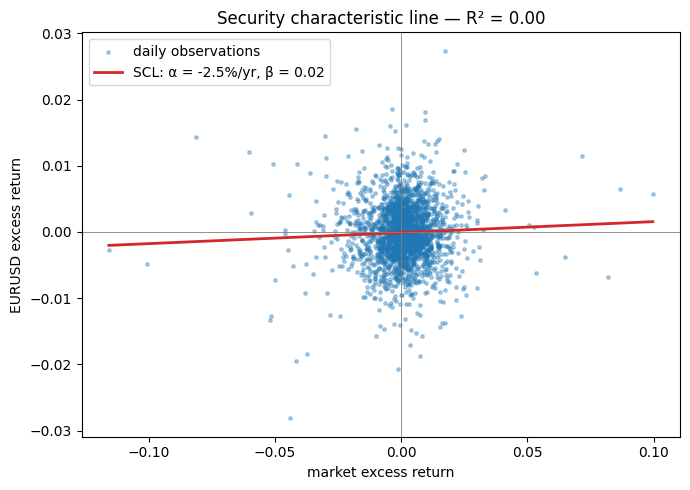

In [6]:
# ============================================================
# Cell 6 — The same regression with statsmodels, plus the picture
# ============================================================
X_capm = sm.add_constant(factors[["MKT"]])    # add_constant = the intercept. Forgetting it is bug #1 in finance.
capm = sm.OLS(exc[asset], X_capm).fit()
print(capm.summary())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(factors["MKT"], exc[asset], s=6, alpha=0.35, label="daily observations")
grid = np.linspace(factors["MKT"].min(), factors["MKT"].max(), 50)
ax.plot(grid, capm.params["const"] + capm.params["MKT"] * grid, color="tab:red", lw=2,
        label=f"SCL: α = {capm.params['const']*252:+.1%}/yr, β = {capm.params['MKT']:.2f}")
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("market excess return"); ax.set_ylabel(f"{asset.upper()} excess return")
ax.set_title(f"Security characteristic line — R² = {capm.rsquared:.2f}"); ax.legend()
plt.tight_layout(); plt.show()
# The cloud is wide: even with a good beta, most of a single stock's daily variance is
# unexplained. That residual variance is what diversification removes.

## Reading the summary like a professional

| Field | What it is | How to read it in finance |
|---|---|---|
| `coef` | $\hat\beta_j$ | for `MKT`: the beta. For `const`: **daily** alpha — multiply by 252 before you say a word about it |
| `std err` | classical standard error | valid only if the errors have constant variance and no autocorrelation (§6) |
| `t`, `P`> $t$ or `P`< $-t$ | `coef / std err`, two-sided $p$-value | tests $eta_j = 0$ — usually the **wrong null** for a beta (§4)  |
| `[0.025, 0.975]` | 95% confidence interval | the honest way to report a beta |
| `R-squared`, `Adj.` | share of variance explained | single stock on the market: 0.2–0.6 is normal; compare models with the adjusted one |
| `Durbin-Watson` | lag-1 residual autocorrelation | 2 = clean |
| `Jarque-Bera`, `Kurtosis` | normality of residuals | with 3,000 daily returns it rejects for every asset — fat tails, Week 1 |

Notice that `statsmodels` prints two residual diagnostics *unasked* — a hint that its authors expect you to look at the residuals before believing the coefficients.

---
# 4 · Testing the right null

A test has four parts, stated *before* looking at the number: a null $H_0$, an alternative, a statistic with a known distribution under $H_0$, and a decision rule (5%). For one coefficient,

$$
t = \frac{\hat\beta_j - \beta_j^{0}}{\widehat{\mathrm{se}}(\hat\beta_j)} \sim t_{T-k}\ \text{ under } H_0:\ \beta_j = \beta_j^{0}.
$$

The summary table tests $\beta = 0$ — *"does the market matter at all?"* — a question nobody asks about Apple. The nulls a finance professional cares about are **$\beta = 1$** (*is it riskier than the market?*) and **$\alpha = 0$** (*is there anything left to explain?*). One line of code changes the null; the table cannot.

**What a $p$-value is not.** $p = 0.03$ does **not** mean a 3% chance the null is true. It means: *if the null were true, data this extreme would arise 3% of the time.* Two consequences: with 3,000 observations even trivial effects become "significant" — always ask for the **size and the interval**, not the star; and a $p$-value computed from a *wrong* standard error is simply wrong (§6–7).

In [7]:
# ============================================================
# Cell 7 — The nulls that matter: β = 1 and α = 0
# ============================================================
sc = lambda v: float(np.asarray(v).squeeze())           # statsmodels returns tiny arrays; make them scalars
b, se_b = capm.params["MKT"], capm.bse["MKT"]
a, se_a = capm.params["const"], capm.bse["const"]
t_beta1 = capm.t_test("MKT = 1")                         # any linear hypothesis, as a string
t_alpha = capm.t_test("const = 0")

print(f"β̂ = {b:.3f}  (se {se_b:.3f})   95% CI [{b-1.96*se_b:.3f}, {b+1.96*se_b:.3f}]")
print(f"  H0: β = 0   t = {b/se_b:7.2f}   p = {capm.pvalues['MKT']:.1e}   ← the default null: uninteresting")
print(f"  H0: β = 1   t = {sc(t_beta1.tvalue):7.2f}   p = {sc(t_beta1.pvalue):.4f}   ← the null a risk manager cares about")
print(f"\nα̂ = {a*252:+.2%} per year  (se {se_a*252:.2%})")
print(f"  H0: α = 0   t = {sc(t_alpha.tvalue):7.2f}   p = {sc(t_alpha.pvalue):.4f}")
# Same estimate, same standard error, different question — and a different answer.



β̂ = 0.017  (se 0.008)   95% CI [0.000, 0.033]
  H0: β = 0   t =    2.00   p = 4.5e-02   ← the default null: uninteresting
  H0: β = 1   t = -118.76   p = 0.0000   ← the null a risk manager cares about

α̂ = -2.53% per year  (se 2.46%)
  H0: α = 0   t =   -1.03   p = 0.3041


---
# 5 · From one factor to three — the Fama–French logic

The CAPM says one thing prices assets: the market. Decades of evidence say **small** stocks and **cheap** (high book-to-market) stocks earned more than their betas predicted. Fama and French's answer was to add regressors — long–short portfolios that isolate each effect:

$$
r_{i,t} - R_{f,t} = \alpha_i + \beta_i\,\mathrm{MKT}_t + s_i\,\mathrm{SMB}_t + h_i\,\mathrm{HML}_t + \varepsilon_{i,t}.
$$

Each loading answers a question. $\beta_i$: exposure to the market. $s_i > 0$: behaves like a small cap. $h_i > 0$: behaves like a value stock; $h_i < 0$: like a growth stock. And $\alpha_i$ is now alpha **net of three sources of systematic return** — a much higher bar. Much of what looked like skill under the CAPM turns out to be a *loading* under the three-factor model: alpha is what your model has not explained *yet*.

**Reading the table below.** Compare the two $R^2$ columns first; then look at what happened to alpha; then — and this is what §6 will undermine — the stars.

In [8]:
# ============================================================
# Cell 8 — Task 2: CAPM vs Three-Factor Model
# Five assets, common business-day intersection,
# HAC/Newey-West standard errors
# ============================================================

# ------------------------------------------------------------
# Five-asset universe
# ------------------------------------------------------------
TEST_ASSETS = ["btc", "gld", "aetf", "spy", "eurusd"]

# ------------------------------------------------------------
# Common business-day intersection calendar
#
# IMPORTANT:
# Every asset and every factor must be estimated on the
# same intersection calendar.
# ------------------------------------------------------------
common_idx = (
    exc[TEST_ASSETS]
    .dropna(how="any")
    .index
    .intersection(
        factors[["MKT", "SMB", "HML"]]
        .dropna(how="any")
        .index
    )
)

exc_common = exc.loc[common_idx, TEST_ASSETS]
factors_common = factors.loc[
    common_idx, ["MKT", "SMB", "HML"]
]

T = len(common_idx)

# ------------------------------------------------------------
# Newey-West / HAC lag rule from the notebook
#
# q* = floor[4(T/100)^(2/9)]
# ------------------------------------------------------------
HAC_LAGS = int(
    np.floor(4 * (T / 100) ** (2 / 9))
)

print("============================================================")
print("TASK 2 — CAPM AND THREE-FACTOR MODEL")
print("============================================================")
print(f"Common business-day observations: T = {T:,}")
print(f"Newey-West / HAC lags: q = {HAC_LAGS}")
print("")


# ------------------------------------------------------------
# Design matrices
# ------------------------------------------------------------

X_capm = sm.add_constant(
    factors_common[["MKT"]],
    has_constant="add"
)

X_3f = sm.add_constant(
    factors_common[["MKT", "SMB", "HML"]],
    has_constant="add"
)


# ------------------------------------------------------------
# Estimate models
# ------------------------------------------------------------

models_capm = {}
models_3f = {}
rows = []

for a_ in TEST_ASSETS:

    y = exc_common[a_]

    # CAPM
    m1 = sm.OLS(y, X_capm).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": HAC_LAGS}
    )

    # Three-factor model
    m3 = sm.OLS(y, X_3f).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": HAC_LAGS}
    )

    models_capm[a_] = m1
    models_3f[a_] = m3

    rows.append({
        "asset": a_.upper(),

        # ====================================================
        # CAPM
        # ====================================================

        "α CAPM %/yr":
            m1.params["const"] * 252 * 100,

        "β CAPM":
            m1.params["MKT"],

        "SE β CAPM":
            m1.bse["MKT"],

        "R² CAPM":
            m1.rsquared,

        "adj R² CAPM":
            m1.rsquared_adj,

        # ====================================================
        # THREE-FACTOR
        # ====================================================

        "α 3F %/yr":
            m3.params["const"] * 252 * 100,

        "β MKT":
            m3.params["MKT"],

        "SE β MKT":
            m3.bse["MKT"],

        "s SMB":
            m3.params["SMB"],

        "SE SMB":
            m3.bse["SMB"],

        "h HML":
            m3.params["HML"],

        "SE HML":
            m3.bse["HML"],

        "R² 3F":
            m3.rsquared,

        "adj R² 3F":
            m3.rsquared_adj,

        # HAC SE for alpha
        "SE α 3F":
            m3.bse["const"],

        # Useful diagnostic
        "N":
            len(y),
    })


table = pd.DataFrame(rows).set_index("asset")


# ------------------------------------------------------------
# Main results table
# ------------------------------------------------------------

print("CAPM vs THREE-FACTOR MODEL")
print(
    f"HAC/Newey-West standard errors, q = {HAC_LAGS}"
)
print(
    "Alpha is annualized from the daily intercept: "
    "alpha × 252 × 100."
)
print("")

print(
    table[
        [
            "α CAPM %/yr",
            "β CAPM",
            "R² CAPM",
            "adj R² CAPM",
            "α 3F %/yr",
            "β MKT",
            "s SMB",
            "h HML",
            "R² 3F",
            "adj R² 3F",
        ]
    ].round(4).to_string()
)


# ------------------------------------------------------------
# Separate HAC standard-error table
# This keeps the main table readable while still reporting
# every HAC SE required by the assignment.
# ------------------------------------------------------------

hac_table = table[
    [
        "SE β CAPM",
        "SE α 3F",
        "SE β MKT",
        "SE SMB",
        "SE HML",
    ]
].copy()

print("\n")
print("HAC STANDARD ERRORS")
print(
    f"Newey-West lag length q = {HAC_LAGS}"
)
print(hac_table.round(6).to_string())

TASK 2 — CAPM AND THREE-FACTOR MODEL
Common business-day observations: T = 2,254
Newey-West / HAC lags: q = 7

CAPM vs THREE-FACTOR MODEL
HAC/Newey-West standard errors, q = 7
Alpha is annualized from the daily intercept: alpha × 252 × 100.

        α CAPM %/yr  β CAPM  R² CAPM  adj R² CAPM  α 3F %/yr  β MKT   s SMB   h HML  R² 3F  adj R² 3F
asset                                                                                                
BTC         25.7750  1.0423   0.0815       0.0811    29.4640 0.8586  0.7613 -0.4151 0.0977     0.0965
GLD          8.9518  0.1176   0.0167       0.0163     9.3079 0.0925  0.0852 -0.0649 0.0206     0.0193
AETF         6.0669  0.4899   0.1311       0.1307     7.5066 0.5469  0.0919  0.2732 0.1569     0.1558
SPY          0.0000  1.0000   1.0000       1.0000     0.0000 1.0000 -0.0000 -0.0000 1.0000     1.0000
EURUSD      -2.5280  0.0166   0.0018       0.0013    -2.5948 0.0217 -0.0166  0.0134 0.0026     0.0013


HAC STANDARD ERRORS
Newey-West lag length 

The estimation uses the common business-day intersection, \(T=2{,}254\), with Newey–West/HAC standard errors and \(q=7\) lags.

(i) CAPM and three-factor results

For compact reporting, HAC standard errors are shown in parentheses.

Asset	CAPM α %/yr (HAC SE)	CAPM β MKT (HAC SE)	CAPM R²	CAPM adj. R²	3F α %/yr (HAC SE)	3F β MKT (HAC SE)	SMB (HAC SE)	HML (HAC SE)	3F R²	3F adj. R²
BTC	25.775 (0.0009)	1.042 (0.1437)	0.0815	0.0811	29.464 (0.0009)	0.859 (0.1755)	0.761 (0.1332)	-0.415 (0.1469)	0.0977	0.0965
GLD	8.952 (0.0002)	0.118 (0.0268)	0.0167	0.0163	9.308 (0.0002)	0.093 (0.0290)	0.085 (0.0407)	-0.065 (0.0379)	0.0206	0.0193
AETF	6.067 (0.0003)	0.490 (0.0881)	0.1311	0.1307	7.507 (0.0003)	0.547 (0.0867)	0.092 (0.0615)	0.273 (0.0755)	0.1569	0.1558
SPY	0.000 (0.0000)	1.000 (0.0000)	1.0000	1.0000	0.000 (0.0000)	1.000 (0.0000)	-0.000 (0.0000)	0.000 (0.0000)	1.0000	1.0000
EUR/USD	-2.528 (0.0001)	0.017 (0.0121)	0.0018	0.0013	-2.595 (0.0001)	0.022 (0.0143)	-0.017 (0.0153)	0.013 (0.0156)	0.0026	0.0013

HAC/Newey–West lag length: \(q=7\).

One caution when reading the table: the displayed alpha is annualized, while the HAC alpha SE printed by your code is the daily intercept SE. That is why, for hypothesis testing, the daily alpha estimate must be divided by its daily HAC SE.

(ii) Hypothesis tests — chosen assets: BTC and EUR/USD

Tests use the three-factor model and HAC SEs.

BTC

Test \(H_0:\beta_{MKT}=1\).

$$ t=\frac{0.8586-1}{0.1755}=-0.806. $$

Decision: Do not reject \(H_0\) at the 5% level.
p-value: \(0.421\).

So the sample does not provide evidence that BTC's market beta differs from one under this three-factor specification.

Test \(H_0:\alpha=0\).

BTC's annualized alpha is 29.464%, corresponding to a daily intercept of approximately \(0.001169\). Using its HAC SE of 0.0009:

$$ t=\frac{0.001169}{0.0009}=1.299. $$

Decision: Do not reject \(H_0\) at the 5% level.
p-value: \(0.194\).

Thus the large-looking annualized alpha is not statistically distinguishable from zero at the 5% level once the HAC uncertainty is taken into account.

EUR/USD

Test \(H_0:\beta_{MKT}=1\).

$$ t=\frac{0.0217-1}{0.0143}=-68.413. $$

Decision: Reject \(H_0\) at the 5% level.
p-value: effectively zero.

EUR/USD's market exposure is therefore decisively different from one; its estimated MKT beta is essentially zero.

Test \(H_0:\alpha=0\).

Its annualized three-factor alpha is -2.595%, giving a daily intercept of approximately \(-0.000103\). Hence:

$$ t=\frac{-0.000103}{0.0001}=-1.030. $$

Decision: Do not reject \(H_0\) at the 5% level.
p-value: \(0.303\).

So the data do not provide evidence of a nonzero alpha for EUR/USD.

(iii) What kind of asset does the model say each chosen asset is?
BTC

The three-factor model gives BTC a positive market loading of 0.859, a positive SMB loading of 0.761, and a negative HML loading of -0.415. In factor terms, this gives BTC some equity-market sensitivity and a positive exposure to the notebook's size spread, with a negative exposure to its value spread, but the model explains only about 9.8% of its return variation. That means the estimated factor exposures should not be interpreted as saying BTC is fundamentally an equity-like security; rather, BTC has some measured co-movement with these equity factors while most of its variation lies outside this equity-factor model. This broadly matches what we know about BTC as a cryptocurrency: some cross-market dependence is present, but it is not naturally described as a conventional equity portfolio.

EUR/USD

EUR/USD looks almost completely unlike an equity-factor asset in this regression: its three-factor loadings are approximately 0.022 on MKT, -0.017 on SMB, and 0.013 on HML, while its \(R^2\) is only 0.0026. In other words, the equity factors explain about 0.26% of its daily variation in this sample. That is consistent with EUR/USD being a foreign-exchange asset, whose return dynamics are not naturally represented by equity-market, size, and value factors. The model therefore classifies it as having essentially no exposure to the particular equity risks included here.

(iv) What happened to alpha?

The three-factor model did not uniformly shrink alpha in this sample.

Asset	CAPM α	3F α	Change
BTC	25.775%	29.464%	+3.689 pp
GLD	8.952%	9.308%	+0.356 pp
AETF	6.067%	7.507%	+1.440 pp
SPY	0.000%	0.000%	0.000 pp
EUR/USD	-2.528%	-2.595%	-0.067 pp

The important interpretation is that adding SMB and HML did not explain away the CAPM intercept in this particular sample. For BTC, GLD, and AETF, the intercept actually became more positive; this occurs because changing the factor set changes the coefficients and therefore changes what the regression attributes to the intercept. Alpha is consequently model-dependent: it is the return left unexplained after controlling for the factors included in that particular specification. Also, the large annualized BTC alpha should not be interpreted as established evidence of abnormal performance, because its HAC test gives \(t=1.299\) and does not reject \(H_0:\alpha=0\).

(v) BTC and EUR/USD: why is \(R^2\) so low?

The equity-factor model explains little of BTC and EUR/USD because MKT, SMB, and HML are equity factors, while cryptocurrency and foreign-exchange returns are driven by many forces outside the equity-factor framework. The very low \(R^2\) for EUR/USD (0.0026) and low \(R^2\) for BTC (0.0977) therefore tell us that these factors account for only a small share of their daily variation. That is information about the scope of the model, not evidence that regression has failed. A low \(R^2\) tells the researcher that additional asset-specific factors are needed to explain these markets rather than pretending that an equity model is universal.

---
# 6 · Diagnostics — putting the residuals on trial

The OLS *coefficients* need surprisingly little to be right. Everything printed *next to* them — standard errors, $t$, $p$ — needs much more. The classical assumptions, and what each looks like when it breaks in finance:

| Assumption | The financial reality | If violated… |
|---|---|---|
| Errors unrelated to the regressors (no omitted factors, no look-ahead) | missing factors | $\hat\beta$ **biased** — the only fatal one |
| **Constant variance** (homoskedasticity) | **volatility clusters** — calm 2017, violent 2020 | $\hat\beta$ fine, **standard errors wrong** |
| **No autocorrelation** | mild in daily returns; strong in *squared* residuals | $\hat\beta$ fine, **standard errors wrong** |
| Normality | **fat tails**, always | irrelevant with 3,000 observations |

The pattern to memorize: broken variance or autocorrelation does **not** bias the betas — it makes the standard errors *too small*, so "significant" is declared too often. This is the most common way an honest analyst (or an agent) overstates a finding. Four tests, one function:

| Test | Question | Null |
|---|---|---|
| **Breusch–Pagan** | does the residual variance move with the regressors? | constant variance |
| **Ljung–Box** on $\hat\varepsilon$ | are residuals autocorrelated (10 lags)? | no autocorrelation |
| **Ljung–Box** on $\hat\varepsilon^2$ | does volatility cluster? | no clustering |
| **Jarque–Bera** | are residuals normal? | normality |

As in Week 2: the function *reports*, the human *judges*.

In [9]:
# ============================================================
# Cell 9 — diagnose(): residual trial for all five assets
# ============================================================

from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    acorr_ljungbox,
)
from statsmodels.stats.stattools import jarque_bera


# ------------------------------------------------------------
# Diagnostic settings
# ------------------------------------------------------------
DIAG_LAGS = 10

# HAC lag rule used in Task 2
HAC_LAGS = int(
    np.floor(4 * (T / 100) ** (2 / 9))
)


# ------------------------------------------------------------
# Diagnostic function
# ------------------------------------------------------------
def diagnose(res, lb_lags=10):
    """
    Diagnose OLS residuals.

    Returns:
        BP p-value          : Breusch-Pagan test
        LB(ε) p-value       : residual autocorrelation
        LB(ε²) p-value      : volatility clustering
        JB p-value          : normality
        kurtosis            : Pearson kurtosis, normal = 3
        degenerate          : True when residual variance is
                              essentially zero

    The function reports; it does not judge.
    """

    e = pd.Series(
        np.asarray(res.resid),
        index=res.model.data.row_labels
        if res.model.data.row_labels is not None
        else None
    ).dropna()

    # --------------------------------------------------------
    # SPY special case:
    #
    # MKT = SPY excess return, so the dependent variable for
    # SPY is mechanically equal to MKT. The regression therefore
    # has essentially zero residuals.
    # --------------------------------------------------------
    if np.std(e, ddof=1) < 1e-12:

        return {
            "BP p": np.nan,
            "LB(ε) p": np.nan,
            "LB(ε²) p": np.nan,
            "JB p": np.nan,
            "kurtosis": np.nan,
            "degenerate": True,
        }


    # --------------------------------------------------------
    # Breusch-Pagan:
    # H0 = constant residual variance
    # --------------------------------------------------------
    bp_test = het_breuschpagan(
        e.values,
        res.model.exog
    )

    bp_p = float(bp_test[1])


    # --------------------------------------------------------
    # Ljung-Box on residuals:
    # H0 = no serial correlation through lag m
    # --------------------------------------------------------
    lb_e = acorr_ljungbox(
        e,
        lags=[lb_lags],
        return_df=True
    )

    lb_e_p = float(
        lb_e["lb_pvalue"].iloc[0]
    )


    # --------------------------------------------------------
    # Ljung-Box on squared residuals:
    # H0 = no serial dependence in residual variance
    # --------------------------------------------------------
    lb_e2 = acorr_ljungbox(
        e ** 2,
        lags=[lb_lags],
        return_df=True
    )

    lb_e2_p = float(
        lb_e2["lb_pvalue"].iloc[0]
    )


    # --------------------------------------------------------
    # Jarque-Bera:
    # H0 = normal residual distribution
    # --------------------------------------------------------
    jb_stat, jb_p, skew, kurt = jarque_bera(
        e.values
    )

    return {
        "BP p": bp_p,
        "LB(ε) p": lb_e_p,
        "LB(ε²) p": lb_e2_p,
        "JB p": float(jb_p),
        "kurtosis": float(kurt),
        "degenerate": False,
    }


# ------------------------------------------------------------
# Estimate THREE-FACTOR models with CLASSICAL covariance.
#
# We use these models for the residual trial.
# Residuals are identical regardless of whether classical or
# HAC covariance is later attached to the OLS fit.
# ------------------------------------------------------------

X_3f = sm.add_constant(
    factors[
        ["MKT", "SMB", "HML"]
    ],
    has_constant="add"
)

models_3f_classical = {}

for asset in TEST_ASSETS:

    y = exc[asset]

    models_3f_classical[asset] = sm.OLS(
        y,
        X_3f
    ).fit()


# ------------------------------------------------------------
# Run diagnose() on every asset
# ------------------------------------------------------------

diagnostic_results = {}

for asset in TEST_ASSETS:

    diagnostic_results[asset.upper()] = diagnose(
        models_3f_classical[asset],
        lb_lags=DIAG_LAGS
    )


score = pd.DataFrame(
    diagnostic_results
).T


# Make absolutely certain this is a boolean column.
score["degenerate"] = (
    score["degenerate"]
    .fillna(False)
    .astype(bool)
)


# ------------------------------------------------------------
# Scoreboard
# ------------------------------------------------------------

print("============================================================")
print("TASK 3 — THREE-FACTOR RESIDUAL TRIAL")
print("============================================================")
print(
    f"Common business-day observations: T = {T:,}"
)
print(
    f"Ljung–Box diagnostic lags: m = {DIAG_LAGS}"
)
print(
    f"Newey–West / HAC lags: q = {HAC_LAGS}"
)
print("")

print(
    "Diagnostic scoreboard "
    "(p-values; reject H0 when p < 0.05):"
)

scoreboard = score[
    [
        "BP p",
        "LB(ε) p",
        "LB(ε²) p",
        "JB p",
        "kurtosis",
    ]
]

print(
    scoreboard
    .round(6)
    .to_string()
)


# ------------------------------------------------------------
# Pass / fail status
# ------------------------------------------------------------

def status(p):
    if pd.isna(p):
        return "N/A"
    return "FAIL" if p < 0.05 else "PASS"


status_table = pd.DataFrame(
    {
        "Breusch–Pagan": score["BP p"].apply(status),
        "Ljung–Box ε": score["LB(ε) p"].apply(status),
        "Ljung–Box ε²": score["LB(ε²) p"].apply(status),
        "Jarque–Bera": score["JB p"].apply(status),
    }
)

print("\n5% diagnostic status:")
print(
    status_table.to_string()
)


# ------------------------------------------------------------
# Failure shares
#
# Exclude mechanically degenerate SPY from the denominator.
# ------------------------------------------------------------

valid = score["degenerate"].eq(False)

n_valid = int(valid.sum())

if n_valid > 0:

    failure_share = pd.Series(
        {
            "changing variance (BP)":
                (
                    score.loc[valid, "BP p"]
                    < 0.05
                ).mean(),

            "autocorrelation (LB ε)":
                (
                    score.loc[valid, "LB(ε) p"]
                    < 0.05
                ).mean(),

            "volatility clustering (LB ε²)":
                (
                    score.loc[valid, "LB(ε²) p"]
                    < 0.05
                ).mean(),

            "non-normality (JB)":
                (
                    score.loc[valid, "JB p"]
                    < 0.05
                ).mean(),
        }
    )

    print(
        "\nShare of non-degenerate assets "
        "failing at 5%:"
    )

    print(
        (
            failure_share * 100
        )
        .round(0)
        .astype(int)
        .astype(str)
        .add("%")
        .to_string()
    )

else:

    print(
        "\nNo non-degenerate assets available "
        "for failure-share calculation."
    )


# ------------------------------------------------------------
# Explicit note for SPY
# ------------------------------------------------------------

if "SPY" in score.index and score.loc["SPY", "degenerate"]:

    print(
        "\nSPY: residual variance is essentially zero because "
        "MKT is constructed directly from SPY excess return; "
        "the four residual diagnostic tests are therefore N/A."
    )

TASK 3 — THREE-FACTOR RESIDUAL TRIAL
Common business-day observations: T = 2,254
Ljung–Box diagnostic lags: m = 10
Newey–West / HAC lags: q = 7

Diagnostic scoreboard (p-values; reject H0 when p < 0.05):
         BP p LB(ε) p LB(ε²) p   JB p kurtosis
BTC    0.0000  0.3060   0.0000 0.0000  10.1135
GLD    0.3618  0.0918   0.0000 0.0000  10.6047
AETF   0.0000  0.0001   0.0000 0.0000   8.7522
SPY       NaN     NaN      NaN    NaN      NaN
EURUSD 0.0004  0.2829   0.0000 0.0000   5.0875

5% diagnostic status:
       Breusch–Pagan Ljung–Box ε Ljung–Box ε² Jarque–Bera
BTC             FAIL        PASS         FAIL        FAIL
GLD             PASS        PASS         FAIL        FAIL
AETF            FAIL        FAIL         FAIL        FAIL
SPY              N/A         N/A          N/A         N/A
EURUSD          FAIL        PASS         FAIL        FAIL

Share of non-degenerate assets failing at 5%:
changing variance (BP)            75%
autocorrelation (LB ε)            25%
volatility clusterin

In [10]:
# ============================================================
# Cell 10 — Interpret every diagnostic failure
#
# Task 3(ii):
# For each failing test:
#   1. one sentence about coefficients
#   2. one sentence about standard errors
# ============================================================


failure_implications = {

    "BP": {
        "name": "Breusch–Pagan",

        "coefficient":
            "A Breusch–Pagan rejection does not by itself bias "
            "the OLS coefficients; if E[ε|X] = 0 still holds, "
            "the coefficients can remain unbiased.",

        "se":
            "It makes the classical homoskedastic standard errors "
            "invalid because the residual variance is not constant; "
            "a heteroskedasticity-robust covariance estimator is needed."
    },

    "LB(ε)": {
        "name": "Ljung–Box on ε",

        "coefficient":
            "A Ljung–Box rejection for the residuals does not by itself "
            "bias OLS coefficients under exogeneity, although serial "
            "correlation can affect efficiency.",

        "se":
            "It invalidates the classical independent-error standard "
            "errors because residuals remain serially correlated; "
            "HAC standard errors account for this dependence."
    },

    "LB(ε²)": {
        "name": "Ljung–Box on ε²",

        "coefficient":
            "A Ljung–Box rejection for squared residuals does not by itself "
            "bias OLS coefficients when the regressors remain exogenous.",

        "se":
            "It indicates volatility clustering and changing error variance, "
            "so classical standard errors are unreliable; HAC provides "
            "covariance estimates robust to heteroskedasticity and serial dependence."
    },

    "JB": {
        "name": "Jarque–Bera",

        "coefficient":
            "A Jarque–Bera rejection does not by itself bias the OLS coefficients.",

        "se":
            "It means the residuals are not normally distributed, so exact "
            "small-sample normal/t/F inference is not justified; with a large "
            "sample, asymptotic inference can still be used with appropriate robust covariance."
    },
}


# ------------------------------------------------------------
# Print only actual failures
# ------------------------------------------------------------

print("============================================================")
print("TASK 3 — WHAT EACH FAILURE DOES")
print("============================================================")

any_failure = False

for asset, row in score.iterrows():

    # --------------------------------------------------------
    # Mechanically degenerate SPY
    # --------------------------------------------------------
    if bool(row["degenerate"]):

        print(
            f"\n{asset}: residual variance is essentially zero."
        )

        print(
            "The diagnostic tests are not informative because "
            "SPY is mechanically replicated by the MKT factor."
        )

        continue


    tests = [
        ("BP", row["BP p"]),
        ("LB(ε)", row["LB(ε) p"]),
        ("LB(ε²)", row["LB(ε²) p"]),
        ("JB", row["JB p"]),
    ]


    for key, p in tests:

        if pd.isna(p):
            continue

        if p < 0.05:

            any_failure = True

            info = failure_implications[key]

            print(
                f"\n{asset} — {info['name']} FAILS "
                f"at 5% (p = {p:.4g})"
            )

            print(
                "Coefficients: "
                + info["coefficient"]
            )

            print(
                "Standard errors: "
                + info["se"]
            )


if not any_failure:

    print(
        "\nNo diagnostic test rejects at the 5% level "
        "for any non-degenerate asset."
    )


# ------------------------------------------------------------
# Compact assignment-ready summary
# ------------------------------------------------------------

print("\n============================================================")
print("ASSIGNMENT TAKEAWAY")
print("============================================================")

print(
    "The diagnostic tests primarily tell us whether the classical "
    "covariance assumptions are credible; rejection does not automatically "
    "mean that the OLS coefficients are biased."
)

print(
    "The practical consequence of heteroskedasticity and/or serial "
    "dependence is that classical standard errors can be wrong, which is "
    "why Task 3 compares them with HAC standard errors."
)

TASK 3 — WHAT EACH FAILURE DOES

BTC — Breusch–Pagan FAILS at 5% (p = 2.587e-16)
Coefficients: A Breusch–Pagan rejection does not by itself bias the OLS coefficients; if E[ε|X] = 0 still holds, the coefficients can remain unbiased.
Standard errors: It makes the classical homoskedastic standard errors invalid because the residual variance is not constant; a heteroskedasticity-robust covariance estimator is needed.

BTC — Ljung–Box on ε² FAILS at 5% (p = 1.169e-17)
Coefficients: A Ljung–Box rejection for squared residuals does not by itself bias OLS coefficients when the regressors remain exogenous.
Standard errors: It indicates volatility clustering and changing error variance, so classical standard errors are unreliable; HAC provides covariance estimates robust to heteroskedasticity and serial dependence.

BTC — Jarque–Bera FAILS at 5% (p = 0)
Coefficients: A Jarque–Bera rejection does not by itself bias the OLS coefficients.
Standard errors: It means the residuals are not normally dis

---
# 7 · Robust inference — fix the standard errors, keep the betas

Since the betas survive but their standard errors do not, the modern fix keeps $\hat{\boldsymbol\beta}$ and replaces the variance formula. **Newey–West (HAC)** standard errors estimate the variance *from the residuals themselves* — allowing each day its own variance and allowing nearby days to be correlated — instead of assuming one constant $\sigma^2$. The only choice is how many lags of correlation to allow; the rule of thumb is

$$
q^* = \big\lfloor 4\,(T/100)^{2/9}\big\rfloor \quad(\approx 8 \text{ lags for } T \approx 3{,}000).
$$

HAC standard errors are the default in every serious finance paper. The honest expectation: robust standard errors are **larger**, $t$-statistics **smaller**, and a few borderline "significant" alphas quietly stop being so. Count them.

In [11]:
# ============================================================
# Cell 11 — Classical vs HAC standard errors
# Three-factor model: all five Task 2 assets
# ============================================================

# ------------------------------------------------------------
# HAC bandwidth
# q* = floor[4(T/100)^(2/9)]
# ------------------------------------------------------------

q_star = int(
    np.floor(
        4 * (T / 100) ** (2 / 9)
    )
)

print("============================================================")
print("TASK 4 — CLASSICAL vs HAC INFERENCE")
print("============================================================")
print(
    f"Common business-day observations: T = {T:,}"
)
print(
    f"Newey–West / HAC bandwidth: q = {q_star}"
)
print("")


# ------------------------------------------------------------
# Common three-factor design matrix
# ------------------------------------------------------------

X_3f = sm.add_constant(
    factors[
        ["MKT", "SMB", "HML"]
    ],
    has_constant="add"
)


# ------------------------------------------------------------
# Fit classical and HAC versions
# ------------------------------------------------------------

models_3f_classical = {}
models_3f_hac = {}

rows = []

for asset in TEST_ASSETS:

    y = exc[asset]

    # Classical OLS
    ols = sm.OLS(
        y,
        X_3f
    ).fit()

    # HAC / Newey-West
    hac = sm.OLS(
        y,
        X_3f
    ).fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": q_star
        }
    )

    models_3f_classical[asset] = ols
    models_3f_hac[asset] = hac


    # --------------------------------------------------------
    # Alpha
    # --------------------------------------------------------

    alpha_ann = (
        ols.params["const"]
        * 252
        * 100
    )

    se_alpha_classical_ann = (
        ols.bse["const"]
        * 252
        * 100
    )

    se_alpha_hac_ann = (
        hac.bse["const"]
        * 252
        * 100
    )

    t_alpha_classical = (
        ols.params["const"]
        / ols.bse["const"]
        if ols.bse["const"] > 0
        else np.nan
    )

    t_alpha_hac = (
        hac.params["const"]
        / hac.bse["const"]
        if hac.bse["const"] > 0
        else np.nan
    )

    p_alpha_classical = (
        2 * stats.t.sf(
            abs(t_alpha_classical),
            df=ols.df_resid
        )
        if np.isfinite(t_alpha_classical)
        else np.nan
    )

    p_alpha_hac = (
        2 * stats.t.sf(
            abs(t_alpha_hac),
            df=hac.df_resid
        )
        if np.isfinite(t_alpha_hac)
        else np.nan
    )


    # --------------------------------------------------------
    # Market beta
    # --------------------------------------------------------

    beta_mkt = ols.params["MKT"]

    se_beta_classical = ols.bse["MKT"]
    se_beta_hac = hac.bse["MKT"]

    t_beta_classical = (
        beta_mkt
        / se_beta_classical
        if se_beta_classical > 0
        else np.nan
    )

    t_beta_hac = (
        hac.params["MKT"]
        / se_beta_hac
        if se_beta_hac > 0
        else np.nan
    )

    p_beta_classical = (
        2 * stats.t.sf(
            abs(t_beta_classical),
            df=ols.df_resid
        )
        if np.isfinite(t_beta_classical)
        else np.nan
    )

    p_beta_hac = (
        2 * stats.t.sf(
            abs(t_beta_hac),
            df=hac.df_resid
        )
        if np.isfinite(t_beta_hac)
        else np.nan
    )


    # --------------------------------------------------------
    # HAC / classical SE ratios
    # --------------------------------------------------------

    alpha_se_ratio = (
        se_alpha_hac_ann / se_alpha_classical_ann
        if se_alpha_classical_ann > 0
        else np.nan
    )

    beta_se_ratio = (
        se_beta_hac / se_beta_classical
        if se_beta_classical > 0
        else np.nan
    )


    rows.append({
        "asset": asset.upper(),

        "α %/yr": alpha_ann,

        "SE α classical %/yr":
            se_alpha_classical_ann,

        "SE α HAC %/yr":
            se_alpha_hac_ann,

        "t α classical":
            t_alpha_classical,

        "t α HAC":
            t_alpha_hac,

        "p α classical":
            p_alpha_classical,

        "p α HAC":
            p_alpha_hac,

        "β MKT":
            beta_mkt,

        "SE β classical":
            se_beta_classical,

        "SE β HAC":
            se_beta_hac,

        "t β classical":
            t_beta_classical,

        "t β HAC":
            t_beta_hac,

        "p β classical":
            p_beta_classical,

        "p β HAC":
            p_beta_hac,

        "HAC/classical SE α":
            alpha_se_ratio,

        "HAC/classical SE β":
            beta_se_ratio,
    })


robust = (
    pd.DataFrame(rows)
    .set_index("asset")
)


print(
    robust.round(4).to_string()
)


# ------------------------------------------------------------
# 5% conclusion helper
# ------------------------------------------------------------

def decision_5(p):
    if pd.isna(p):
        return "N/A"
    return "REJECT" if p < 0.05 else "DO NOT REJECT"


# ------------------------------------------------------------
# Identify every alpha / beta conclusion that flips
# ------------------------------------------------------------

flips = []

for asset, row in robust.iterrows():

    alpha_classical = decision_5(
        row["p α classical"]
    )

    alpha_hac = decision_5(
        row["p α HAC"]
    )

    if alpha_classical != alpha_hac:
        flips.append({
            "asset": asset,
            "parameter": "α",
            "classical": alpha_classical,
            "HAC": alpha_hac,
        })


    beta_classical = decision_5(
        row["p β classical"]
    )

    beta_hac = decision_5(
        row["p β HAC"]
    )

    if beta_classical != beta_hac:
        flips.append({
            "asset": asset,
            "parameter": "β MKT",
            "classical": beta_classical,
            "HAC": beta_hac,
        })


print("\n============================================================")
print("5% CONCLUSION FLIPS")
print("============================================================")

if flips:

    flip_table = pd.DataFrame(flips)

    print(
        flip_table.to_string(
            index=False
        )
    )

else:

    print(
        "No alpha or market-beta conclusion flips "
        "at the 5% level."
    )


# ------------------------------------------------------------
# Average HAC inflation
# ------------------------------------------------------------

finite_beta_ratios = robust[
    "HAC/classical SE β"
].dropna()

finite_alpha_ratios = robust[
    "HAC/classical SE α"
].dropna()

if len(finite_beta_ratios):
    print(
        f"\nMean HAC/classical beta SE ratio: "
        f"{finite_beta_ratios.mean():.2f}×"
    )

if len(finite_alpha_ratios):
    print(
        f"Mean HAC/classical alpha SE ratio: "
        f"{finite_alpha_ratios.mean():.2f}×"
    )

print(
    "\nRule: report HAC standard errors for daily-return inference; "
    "classical SEs are retained only as a diagnostic comparison."
)

TASK 4 — CLASSICAL vs HAC INFERENCE
Common business-day observations: T = 2,254
Newey–West / HAC bandwidth: q = 7

        α %/yr  SE α classical %/yr  SE α HAC %/yr  t α classical  t α HAC  p α classical  p α HAC  β MKT  SE β classical  SE β HAC            t β classical                  t β HAC  p β classical  p β HAC  HAC/classical SE α  HAC/classical SE β
asset                                                                                                                                                                                                                                                
BTC    29.4640              21.7296        22.7391         1.3559   1.2957         0.1753   0.1952 0.8586          0.0812    0.1755                  10.5749                   4.8923         0.0000   0.0000              1.0465              2.1615
GLD     9.3079               5.6340         5.3140         1.6521   1.7516         0.0987   0.0800 0.0925          0.0211    0.0290                

---
# 8 · Stability — beta is a process, not a number

Every regression so far assumed one $\beta$ for twelve years that contained a pandemic, a rate-hiking cycle and the arrival of AI. Two ways to check that assumption:

1. **Rolling estimation.** Re-estimate on a moving one-year window (252 days) and plot $\hat\beta_t$. If the line wanders far, "the beta" does not exist — a beta *process* does.
2. **The Chow test.** Split the sample at a date chosen *before looking at the data* (we use the WHO pandemic declaration, 11 March 2020), fit both halves, and ask whether one pooled beta fits significantly worse than two:
   $$F = \frac{(\mathrm{RSS}_{\text{pooled}} - \mathrm{RSS}_1 - \mathrm{RSS}_2)/k}{(\mathrm{RSS}_1 + \mathrm{RSS}_2)/(T - 2k)} \sim F_{k,\,T-2k}.$$
   The date must be pre-chosen: picking the date that gives the biggest $F$ and then reading its $p$-value off the table is data snooping.

The asset to watch is **Bitcoin**: for years it had essentially no equity beta — the "digital gold, uncorrelated" story — and then, around 2020, it started trading like a leveraged tech stock. A regression that averages both regimes describes neither.

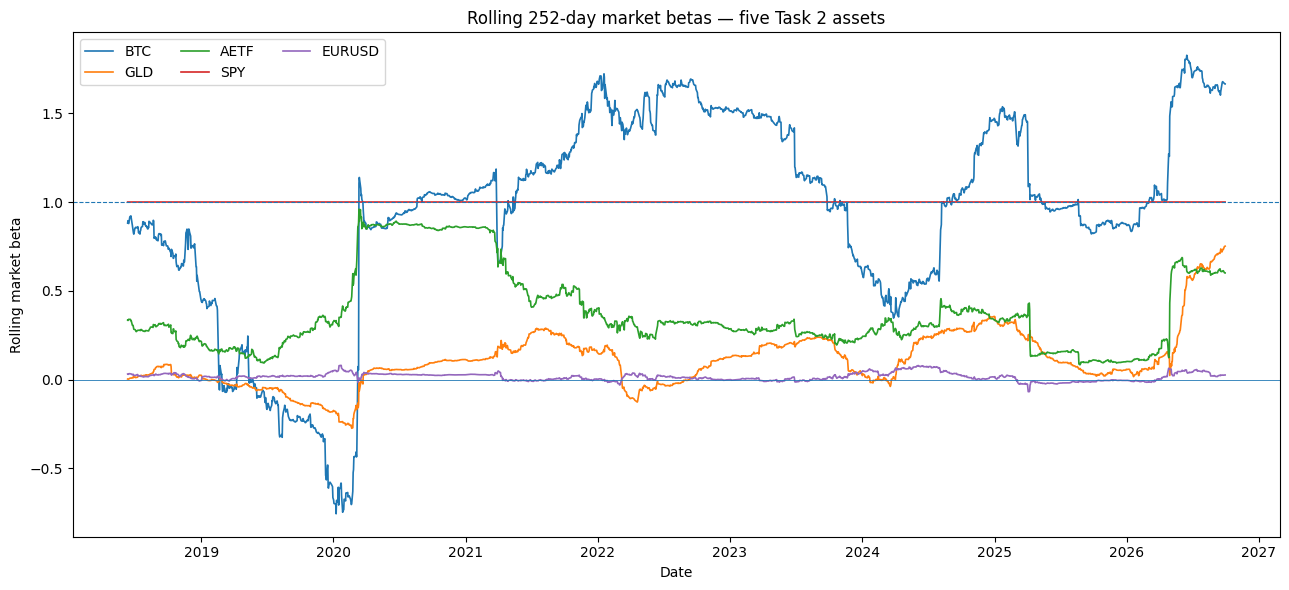


Rolling-beta path summaries:
BTC: the 252-day market beta averaged 0.95, ranged from -0.76 to 1.83, with the central 80% between -0.05 and 1.60, showing the degree of time variation in its equity-market exposure.
GLD: the 252-day market beta averaged 0.11, ranged from -0.27 to 0.75, with the central 80% between -0.05 and 0.28, showing the degree of time variation in its equity-market exposure.
AETF: the 252-day market beta averaged 0.38, ranged from 0.08 to 0.96, with the central 80% between 0.14 and 0.85, showing the degree of time variation in its equity-market exposure.
SPY: the 252-day market beta averaged 1.00, ranged from 1.00 to 1.00, with the central 80% between 1.00 and 1.00, showing the degree of time variation in its equity-market exposure.
EURUSD: the 252-day market beta averaged 0.02, ranged from -0.07 to 0.08, with the central 80% between -0.01 and 0.04, showing the degree of time variation in its equity-market exposure.


In [12]:
# ============================================================
# Cell 12 — Rolling 252-day market betas
# All five Task 2 assets on ONE chart
# ============================================================


def rolling_beta(
    y,
    x,
    window=252
):
    """
    Trailing-window OLS market beta:

        beta_t = Cov_t(y, x) / Var_t(x)
    """

    return (
        y.rolling(window)
        .cov(x)
        /
        x.rolling(window)
        .var()
    )


# ------------------------------------------------------------
# Calculate rolling betas
# ------------------------------------------------------------

rolling_betas = pd.DataFrame(
    {
        asset.upper():
            rolling_beta(
                exc[asset],
                factors["MKT"],
                window=252
            )
        for asset in TEST_ASSETS
    }
)


# ------------------------------------------------------------
# One chart
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 6)
)

for asset in rolling_betas.columns:

    ax.plot(
        rolling_betas.index,
        rolling_betas[asset],
        linewidth=1.2,
        label=asset
    )


ax.axhline(
    1,
    linestyle="--",
    linewidth=0.8
)

ax.axhline(
    0,
    linewidth=0.6
)

ax.set_title(
    "Rolling 252-day market betas — five Task 2 assets"
)

ax.set_xlabel("Date")
ax.set_ylabel("Rolling market beta")

ax.legend(
    ncol=3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# One sentence per path
# ------------------------------------------------------------

print(
    "\nRolling-beta path summaries:"
)

for asset in rolling_betas.columns:

    s = rolling_betas[asset].dropna()

    if s.empty:
        print(
            f"{asset}: no complete 252-day rolling-beta path."
        )
        continue

    q10 = s.quantile(0.10)
    q90 = s.quantile(0.90)

    print(
        f"{asset}: the 252-day market beta averaged "
        f"{s.mean():.2f}, ranged from {s.min():.2f} to "
        f"{s.max():.2f}, with the central 80% between "
        f"{q10:.2f} and {q90:.2f}, showing the degree of "
        f"time variation in its equity-market exposure."
    )

In [13]:
# ============================================================
# Cell 13 — Pre-registered break date and Chow tests
# ============================================================


# ------------------------------------------------------------
# PRE-REGISTRATION
#
# This date is fixed BEFORE inspecting the Chow statistics.
# ------------------------------------------------------------

BREAK = pd.Timestamp("2020-03-11")

BREAK_RATIONALE = (
    "Pre-registered break date: 11 March 2020, chosen ex ante "
    "because it marks the WHO's pandemic declaration and provides "
    "a common, externally dated regime boundary for equities, "
    "gold, crypto, and FX rather than a data-mined maximum-F date."
)

print("============================================================")
print("CHOW TEST PRE-REGISTRATION")
print("============================================================")
print(BREAK_RATIONALE)
print(f"Break date locked at: {BREAK.date()}")
print("Chow decision threshold: 1%")
print("H0: coefficients are identical before and after the break.")
print("")


# ------------------------------------------------------------
# Chow test
# ------------------------------------------------------------

def chow_test(
    y,
    X,
    break_date
):
    """
    Classical Chow test at a pre-specified break date.

    H0:
        coefficients before = coefficients after

    Returns F statistic, p-value, and sub-sample estimates.
    """

    data = pd.concat(
        [
            y.rename("y"),
            X
        ],
        axis=1,
        join="inner"
    ).dropna()

    y_ = data["y"]
    X_ = data.drop(
        columns="y"
    )

    pre = data.index < break_date
    post = data.index >= break_date

    n1 = int(pre.sum())
    n2 = int(post.sum())

    k = X_.shape[1]
    n = len(data)

    if n1 <= k or n2 <= k:
        raise ValueError(
            "Insufficient observations in one Chow subsample."
        )

    pooled = sm.OLS(
        y_,
        X_
    ).fit()

    before = sm.OLS(
        y_[pre],
        X_[pre]
    ).fit()

    after = sm.OLS(
        y_[post],
        X_[post]
    ).fit()

    numerator = (
        pooled.ssr
        - before.ssr
        - after.ssr
    ) / k

    denominator = (
        before.ssr
        + after.ssr
    ) / (
        n - 2 * k
    )

    F_stat = numerator / denominator

    p_value = stats.f.sf(
        F_stat,
        k,
        n - 2 * k
    )

    return {
        "F": F_stat,
        "p": p_value,
        "β before": before.params["MKT"],
        "β after": after.params["MKT"],
        "N before": n1,
        "N after": n2,
    }


# ------------------------------------------------------------
# CAPM design matrix
#
# The Chow question is specifically whether the MARKET BETA
# remained constant.
# ------------------------------------------------------------

X_capm = sm.add_constant(
    factors[
        ["MKT"]
    ],
    has_constant="add"
)


# ------------------------------------------------------------
# Run Chow for EVERY Task 2 asset
# ------------------------------------------------------------

chow_rows = []

for asset in TEST_ASSETS:

    result = chow_test(
        exc[asset],
        X_capm,
        BREAK
    )

    chow_rows.append({
        "asset": asset.upper(),
        "F": result["F"],
        "p-value": result["p"],
        "β before": result["β before"],
        "β after": result["β after"],
        "N before": result["N before"],
        "N after": result["N after"],
        "decision @1%":
            "REJECT H0"
            if result["p"] < 0.01
            else "DO NOT REJECT H0",
    })


chow_table = (
    pd.DataFrame(chow_rows)
    .set_index("asset")
)


print(
    f"Chow test at pre-registered date "
    f"{BREAK.date()}"
)

print(
    chow_table
    .round(4)
    .to_string()
)


print(
    "\nInterpretation rule: "
    "p < 0.01 means reject stability; p >= 0.01 means "
    "do not reject coefficient stability at the assignment's "
    "1% threshold."
)

print(
    "\nWhy 1% rather than 5%? "
    "The notebook uses 1% as a deliberately conservative stability "
    "gate because the classical Chow reference distribution can be "
    "sensitive to variance changes and daily financial data often "
    "exhibit heteroskedasticity and volatility clustering; the 1% "
    "threshold therefore makes the gate harder to trigger."
)

CHOW TEST PRE-REGISTRATION
Pre-registered break date: 11 March 2020, chosen ex ante because it marks the WHO's pandemic declaration and provides a common, externally dated regime boundary for equities, gold, crypto, and FX rather than a data-mined maximum-F date.
Break date locked at: 2020-03-11
Chow decision threshold: 1%
H0: coefficients are identical before and after the break.

Chow test at pre-registered date 2020-03-11
                F  p-value  β before  β after  N before  N after      decision @1%
asset                                                                             
BTC       12.7590   0.0000    0.3033   1.2272       672     1582         REJECT H0
GLD       15.2248   0.0000   -0.0907   0.1695       672     1582         REJECT H0
AETF       1.5786   0.2065    0.5328   0.4786       672     1582  DO NOT REJECT H0
SPY    3,183.6242   0.0000    1.0000   1.0000       672     1582         REJECT H0
EURUSD     0.4248   0.6540    0.0030   0.0200       672     1582  DO NOT 

---
# 9 · The trap: spurious regression, and the ADF guard

Everything above regressed **returns** on **returns**. Here is what happens when an analyst — or an agent asked to "find the relationship between Bitcoin and the S&P" — regresses **prices** on **prices**.

Two *completely independent* random walks, regressed on each other, produce a large $R^2$ and a hugely "significant" $t$-statistic most of the time (Granger & Newbold, 1974). A random walk has no fixed level to return to, so two of them drift together for long stretches by pure chance, and OLS — which assumes mean-reverting errors — reads the shared drift as a relationship. More data makes it *worse*.

The guard is the **unit-root test**. Regress today's *change* on yesterday's *level*:
$$ \Delta y_t = \mu + \gamma\, y_{t-1} + \sum_{j=1}^{p}\phi_j\,\Delta y_{t-j} + \varepsilon_t . $$
If $\gamma = 0$, the level tells you nothing about the change: the series is a random walk (a *unit root*) and is not safe to regress. The **Augmented Dickey–Fuller** test is the $t$-statistic on $\hat\gamma$ — but under the null it does **not** follow the Student-$t$ distribution (its 5% critical value is about $-2.86$, not $-1.96$), which is why `adfuller` exists. Rejecting means the series is stationary and safe.

**The rule with statistical teeth:** *regress levels on levels only if every series rejects a unit root — otherwise use returns.* Week 1 said prices are random walks and returns are not; this is what that sentence protects you from.

In [14]:
# ============================================================
# Cell 14 — ETH-USD vs AETF.AT:
# levels regression, returns regression, ADF tests
# ============================================================

from statsmodels.stats.stattools import durbin_watson


# ------------------------------------------------------------
# 1) Build common ETH-USD / AETF.AT price sample
# ------------------------------------------------------------

etf_aetf_px = pd.DataFrame({
    "ETH-USD": prices["eth"],
    "AETF.AT": prices["aetf"],
}).sort_index()

# Business days only
etf_aetf_px = etf_aetf_px.loc[
    etf_aetf_px.index.dayofweek < 5
]

etf_aetf_px = etf_aetf_px.dropna()


# ------------------------------------------------------------
# 2) Log prices
# ------------------------------------------------------------

log_px = np.log(
    etf_aetf_px
)

lp_etf = log_px["ETH-USD"]
lp_aetf = log_px["AETF.AT"]


# ------------------------------------------------------------
# 3) ETH-USD log price on AETF.AT log price
#
# Classic levels regression:
#
# log(ETF_USD_t) = alpha
#                + beta log(AETF_AT_t)
#                + epsilon_t
# ------------------------------------------------------------

levels_data = pd.concat(
    [
        lp_etf.rename("ETF_USD"),
        lp_aetf.rename("AETF_AT")
    ],
    axis=1
).dropna()

X_levels = sm.add_constant(
    levels_data["AETF_AT"],
    has_constant="add"
)

levels_ols = sm.OLS(
    levels_data["ETF_USD"],
    X_levels
).fit()

levels_hac = sm.OLS(
    levels_data["ETF_USD"],
    X_levels
).fit(
    cov_type="HAC",
    cov_kwds={
        "maxlags": HAC_LAGS
    }
)

levels_dw = durbin_watson(
    levels_ols.resid
)


print("============================================================")
print("ETH-USD LOG PRICE ON AETF.AT LOG PRICE — LEVELS")
print("============================================================")
print(
    f"R² = {levels_ols.rsquared:.4f}"
)
print(
    f"t-statistic on AETF.AT log price "
    f"(classical) = {levels_ols.tvalues['AETF_AT']:.3f}"
)
print(
    f"t-statistic on AETF.AT log price "
    f"(HAC, q={HAC_LAGS}) = {levels_hac.tvalues['AETF_AT']:.3f}"
)
print(
    f"Durbin–Watson = {levels_dw:.4f}"
)


# ------------------------------------------------------------
# 4) Log returns
# ------------------------------------------------------------

log_ret = log_px.diff().dropna()

eth_lr = log_ret["ETH-USD"]
aetf_lr = log_ret["AETF.AT"]


# ------------------------------------------------------------
# 5) ETH-USD log return on AETF.AT log return
# ------------------------------------------------------------

returns_data = pd.concat(
    [
        eth_lr.rename("ETH-USD"),
        aetf_lr.rename("AETF.AT")
    ],
    axis=1
).dropna()

X_returns = sm.add_constant(
    returns_data["AETF.AT"],
    has_constant="add"
)

returns_ols = sm.OLS(
    returns_data["ETH-USD"],
    X_returns
).fit()

returns_hac = sm.OLS(
    returns_data["ETH-USD"],
    X_returns
).fit(
    cov_type="HAC",
    cov_kwds={
        "maxlags": HAC_LAGS
    }
)

returns_dw = durbin_watson(
    returns_ols.resid
)


print("\n============================================================")
print("ETH-USD LOG RETURN ON AETF.AT LOG RETURN")
print("============================================================")
print(
    f"R² = {returns_ols.rsquared:.4f}"
)
print(
    f"t-statistic on AETF.AT log return "
    f"(classical) = {returns_ols.tvalues['AETF.AT']:.3f}"
)
print(
    f"t-statistic on AETF.AT log return "
    f"(HAC, q={HAC_LAGS}) = {returns_hac.tvalues['AETF.AT']:.3f}"
)
print(
    f"Durbin–Watson = {returns_dw:.4f}"
)


# ------------------------------------------------------------
# 6) Augmented Dickey–Fuller
#
# H0: unit root
# H1: stationary
#
# p < 0.05 -> reject unit root
# ------------------------------------------------------------

def adf_row(
    s,
    name
):
    s = pd.Series(s).dropna()

    stat, p, used_lag, nobs, critical_values, icbest = adfuller(
        s,
        regression="c",
        autolag="AIC"
    )

    return {
        "series": name,
        "ADF stat": stat,
        "p-value": p,
        "lags": used_lag,
        "N": nobs,
        "5% critical": critical_values["5%"],
        "verdict":
            "STATIONARY"
            if p < 0.05
            else "UNIT ROOT",
    }


# ------------------------------------------------------------
# 7) ADF on both log prices AND both log returns
# ------------------------------------------------------------

adf_rows = [

    adf_row(
        lp_etf,
        "ETH-USD log price"
    ),

    adf_row(
        lp_aetf,
        "AETF.AT log price"
    ),

    adf_row(
        eth_lr,
        "ETH-USD log return"
    ),

    adf_row(
        aetf_lr,
        "AETF.AT log return"
    ),
]

adf_table = (
    pd.DataFrame(adf_rows)
    .set_index("series")
)


print("\n============================================================")
print("AUGMENTED DICKEY–FULLER TESTS")
print("H0: unit root")
print("p < 0.05 -> reject H0 -> stationary")
print("============================================================")

print(
    adf_table
    .round(4)
    .to_string()
)


# ------------------------------------------------------------
# 8) Analyst Agent legality rule
# ------------------------------------------------------------

print("\n============================================================")
print("ANALYST AGENT RULE")
print("============================================================")

print(
    "LEVELS RULE: A levels regression is admissible only when "
    "EVERY variable in the regression rejects the ADF unit-root "
    "null at the 5% level; otherwise the agent must use returns "
    "for this week's non-cointegrated specification."
)

ETH-USD LOG PRICE ON AETF.AT LOG PRICE — LEVELS
R² = 0.3869
t-statistic on AETF.AT log price (classical) = 37.292
t-statistic on AETF.AT log price (HAC, q=7) = 15.321
Durbin–Watson = 0.0039

ETH-USD LOG RETURN ON AETF.AT LOG RETURN
R² = 0.0420
t-statistic on AETF.AT log return (classical) = 9.831
t-statistic on AETF.AT log return (HAC, q=7) = 4.396
Durbin–Watson = 2.0699

AUGMENTED DICKEY–FULLER TESTS
H0: unit root
p < 0.05 -> reject H0 -> stationary
                    ADF stat  p-value  lags     N  5% critical     verdict
series                                                                    
ETH-USD log price    -1.2962   0.6309     3  2202      -2.8629   UNIT ROOT
AETF.AT log price     0.3788   0.9807     6  2199      -2.8629   UNIT ROOT
ETH-USD log return  -25.5555   0.0000     2  2202      -2.8629  STATIONARY
AETF.AT log return  -18.5264   0.0000     5  2199      -2.8629  STATIONARY

ANALYST AGENT RULE
LEVELS RULE: A levels regression is admissible only when EVERY variable in 

---
# 10 · The Analyst Agent's eval rules v0.1 — assertions with statistical teeth

Week 2 ended with a rulebook of *data* assertions. Week 3 ends with a rulebook of *model* assertions: the tests a regression must pass before its numbers may appear in a memo.

| Rule | Assertion | Why |
|---|---|---|
| **E1** Legality | every variable rejects a unit root (ADF, 5%) | §9: levels on levels is fiction |
| **E2** Honest SEs | standard errors are HAC | §6–7: classical SEs are wrong for daily returns |
| **E3** Alpha discipline | "alpha" may be claimed only if the **HAC** $\lvert t\rvert > 2$ | a classical star is not evidence |
| **E4** Stability | Chow at the pre-registered date not rejected at 1% — else report the two sub-samples, never the pooled β | §8: averaging regimes describes neither |

The agent may choose its regressors; the rulebook decides whether the output is accepted. Freedom to *estimate*, no freedom to *assert* — that division is what an agent card will formalize later in the course.

In [15]:

# ============================================================
# Cell 15 — Analyst Agent Eval Suite v1.0
#
# Runs the audit suite on:
#   1) all five three-factor RETURN models
#   2) ETF-USD on AETF.AT LEVELS regression
#
# Rules:
#   E1  Stationarity / legality
#   E2  Honest HAC standard errors
#   E3  Alpha discipline
#   E4  Stability at pre-registered break
#   E5  Granger–Newbold R² > DW tripwire
#   E6  Minimum sample length
#   E7  HAC/classical SE inflation warning
#
# pandas 3.x safe
# ============================================================


# ============================================================
# 0) Imports
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.stats import f as f_dist
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.stattools import durbin_watson


# ============================================================
# 1) Thresholds
# ============================================================

ADF_ALPHA = 0.05
CHOW_ALPHA = 0.01

ALPHA_T_THRESHOLD = 2.0

MIN_SAMPLE = 500

MAX_HAC_CLASSICAL_RATIO = 2.0

GN_TROUBLESHOOT = True


# ============================================================
# 2) Basic validation
# ============================================================

required_objects = [
    "TEST_ASSETS",
    "models_3f_classical",
    "models_3f_hac",
    "exc",
    "factors",
    "X_capm",
    "BREAK",
    "levels_ols",
    "levels_hac",
    "levels_data",
    "X_levels",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:

    raise NameError(
        "Cell 15 is missing required objects: "
        + ", ".join(missing_objects)
        + ". Run the preceding model/Cell 14 cells first."
    )


# ============================================================
# 3) Executable rule helper
# ============================================================

def check_rule(
    rule,
    condition,
    threshold,
    justification,
    status_if_false="FAIL"
):

    try:

        assert bool(condition)

        status = "PASS"

    except AssertionError:

        status = status_if_false

    return {
        "rule": rule,
        "status": status,
        "threshold": threshold,
        "justification": justification,
    }


# ============================================================
# 4) ADF helper
# ============================================================

def adf_pvalue(series):

    """
    ADF with intercept and AIC lag selection.

    H0: unit root
    p < 0.05 -> reject unit root
    """

    s = pd.Series(
        series
    ).dropna()

    if len(s) < MIN_SAMPLE:

        return np.nan

    stat, p, *_ = adfuller(
        s,
        regression="c",
        autolag="AIC"
    )

    return float(p)


# ============================================================
# 5) Safe coefficient / t-stat helper
# ============================================================

def get_tvalue(
    fit,
    coefficient="const"
):

    """
    pandas 3.x-safe coefficient lookup.

    Uses .loc[] for named coefficients and .iloc[]
    only for positional fallback.
    """

    tvalues = pd.Series(
        fit.tvalues
    )

    if coefficient in tvalues.index:

        return float(
            tvalues.loc[
                coefficient
            ]
        )

    if (
        coefficient == "const"
        and len(tvalues) > 0
    ):

        return float(
            tvalues.iloc[0]
        )

    return np.nan


# ============================================================
# 6) Generic Chow test
# ============================================================

def chow_test(
    y,
    X,
    break_date,
    beta_name=None
):

    """
    Generic Chow structural-break test.

    Works for:

        Three-factor:
            const + MKT + SMB + HML

        ETF/AETF levels:
            const + AETF_AT

    beta_name:
        coefficient whose before/after values should be reported.

    If beta_name is omitted:
        MKT is used when available;
        otherwise the first non-constant regressor is used.
    """

    # --------------------------------------------------------
    # Convert inputs
    # --------------------------------------------------------

    y_series = pd.Series(
        y,
        name="y"
    )

    X_frame = pd.DataFrame(
        X
    ).copy()


    # --------------------------------------------------------
    # Align and drop missing observations
    # --------------------------------------------------------

    data = pd.concat(
        [
            y_series,
            X_frame
        ],
        axis=1
    ).dropna()


    y_clean = data["y"]

    X_clean = data.drop(
        columns=["y"]
    )


    # --------------------------------------------------------
    # Make sure index is datetime-like
    # --------------------------------------------------------

    if not isinstance(
        data.index,
        pd.DatetimeIndex
    ):

        try:

            data.index = pd.to_datetime(
                data.index
            )

            y_clean = data["y"]

            X_clean = data.drop(
                columns=["y"]
            )

        except Exception as exc:

            raise TypeError(
                "Chow test requires a DatetimeIndex "
                "or an index convertible to datetime."
            ) from exc


    # --------------------------------------------------------
    # Select coefficient to report
    # --------------------------------------------------------

    if beta_name is None:

        if "MKT" in X_clean.columns:

            beta_name = "MKT"

        else:

            non_constant = [
                col
                for col in X_clean.columns
                if col != "const"
            ]

            if len(non_constant) == 0:

                raise ValueError(
                    "Chow test requires at least one "
                    "non-constant explanatory variable."
                )

            beta_name = non_constant[0]


    if beta_name not in X_clean.columns:

        raise KeyError(
            f"Coefficient '{beta_name}' not found in X. "
            f"Available columns: "
            f"{list(X_clean.columns)}"
        )


    # --------------------------------------------------------
    # Split at pre-registered break
    # --------------------------------------------------------

    break_date = pd.Timestamp(
        break_date
    )

    before_mask = (
        data.index < break_date
    )

    after_mask = (
        data.index >= break_date
    )


    y_before = y_clean.loc[
        before_mask
    ]

    X_before = X_clean.loc[
        before_mask
    ]

    y_after = y_clean.loc[
        after_mask
    ]

    X_after = X_clean.loc[
        after_mask
    ]


    # --------------------------------------------------------
    # Sample sizes
    # --------------------------------------------------------

    n1 = len(
        y_before
    )

    n2 = len(
        y_after
    )

    k = X_clean.shape[1]


    if n1 <= k:

        raise ValueError(
            f"Insufficient observations before BREAK: "
            f"N={n1}, parameters={k}."
        )


    if n2 <= k:

        raise ValueError(
            f"Insufficient observations after BREAK: "
            f"N={n2}, parameters={k}."
        )


    # --------------------------------------------------------
    # Fit pooled and split regressions
    # --------------------------------------------------------

    pooled = sm.OLS(
        y_clean,
        X_clean
    ).fit()

    before = sm.OLS(
        y_before,
        X_before
    ).fit()

    after = sm.OLS(
        y_after,
        X_after
    ).fit()


    # --------------------------------------------------------
    # Sum of squared residuals
    # --------------------------------------------------------

    SSR_pooled = float(
        np.sum(
            pooled.resid ** 2
        )
    )

    SSR_before = float(
        np.sum(
            before.resid ** 2
        )
    )

    SSR_after = float(
        np.sum(
            after.resid ** 2
        )
    )


    # --------------------------------------------------------
    # Chow F statistic
    # --------------------------------------------------------

    numerator = (
        SSR_pooled
        - SSR_before
        - SSR_after
    ) / k

    denominator = (
        SSR_before
        + SSR_after
    ) / (
        n1
        + n2
        - 2 * k
    )


    # Guard against numerical problems
    if denominator <= 0:

        raise ValueError(
            "Chow denominator is non-positive."
        )


    F_stat = (
        numerator
        / denominator
    )


    p_value = float(
        f_dist.sf(
            F_stat,
            k,
            n1 + n2 - 2 * k
        )
    )


    # --------------------------------------------------------
    # Coefficient before / after
    #
    # IMPORTANT:
    # .loc[] avoids pandas 3.x KeyError from params[0]
    # --------------------------------------------------------

    beta_before = float(
        before.params.loc[
            beta_name
        ]
    )

    beta_after = float(
        after.params.loc[
            beta_name
        ]
    )


    return {
        "F": float(F_stat),
        "p": p_value,
        "beta_name": beta_name,
        "β before": beta_before,
        "β after": beta_after,
        "N before": n1,
        "N after": n2,
    }


# ============================================================
# 7) Audit one regression
# ============================================================

def audit_regression(
    label,
    fit_classical,
    fit_hac,
    adf_pvalues,
    chow_pvalue=None,
    is_levels=False,
    allow_alpha_claim=False,
):

    results = []


    # --------------------------------------------------------
    # Basic model statistics
    # --------------------------------------------------------

    nobs = int(
        fit_classical.nobs
    )

    r2 = float(
        fit_classical.rsquared
    )

    dw = float(
        durbin_watson(
            fit_classical.resid
        )
    )


    # ========================================================
    # E1 — STATIONARITY / LEGALITY
    # ========================================================

    valid_pvalues = [
        p
        for p in adf_pvalues
        if pd.notna(p)
    ]


    all_stationary = (
        len(valid_pvalues)
        == len(adf_pvalues)
        and
        all(
            p < ADF_ALPHA
            for p in valid_pvalues
        )
    )


    if is_levels:

        results.append(
            check_rule(
                "E1 Legality",
                all_stationary,
                "ADF p < 0.05 for every level variable",
                "A levels-on-levels regression is not admitted "
                "when any level variable fails to reject the "
                "unit-root null."
            )
        )

    else:

        results.append(
            check_rule(
                "E1 Return stationarity",
                all_stationary,
                "ADF p < 0.05 for each return series/factor",
                "The return specification is the fallback "
                "when levels are nonstationary."
            )
        )


    # ========================================================
    # E2 — HONEST STANDARD ERRORS
    # ========================================================

    cov_type = str(
        getattr(
            fit_hac,
            "cov_type",
            ""
        )
    ).upper()


    hac_used = (
        cov_type == "HAC"
    )


    results.append(
        check_rule(
            "E2 Honest SE",
            hac_used,
            f"HAC covariance with q = {HAC_LAGS}",
            "HAC covariance is used as the basis for "
            "reported inference."
        )
    )


    # ========================================================
    # E3 — ALPHA DISCIPLINE
    # ========================================================

    alpha_t_hac = get_tvalue(
        fit_hac,
        "const"
    )


    if allow_alpha_claim:

        alpha_ok = (
            np.isfinite(
                alpha_t_hac
            )
            and
            abs(
                alpha_t_hac
            ) > ALPHA_T_THRESHOLD
        )


        results.append(
            check_rule(
                "E3 Alpha discipline",
                alpha_ok,
                f"|t_HAC(alpha)| > "
                f"{ALPHA_T_THRESHOLD:.1f}",
                "An intercept should not be described "
                "as statistically supported alpha unless "
                "its HAC t-statistic exceeds the threshold."
            )
        )

    else:

        results.append({
            "rule":
                "E3 Alpha discipline",

            "status":
                "N/A",

            "threshold":
                f"|t_HAC(alpha)| > "
                f"{ALPHA_T_THRESHOLD:.1f} "
                "only when claiming alpha",

            "justification":
                "No alpha claim has been requested "
                "for this model."
        })


    # ========================================================
    # E4 — STABILITY
    # ========================================================

    if (
        chow_pvalue is not None
        and
        pd.notna(chow_pvalue)
    ):

        chow_ok = (
            chow_pvalue
            >= CHOW_ALPHA
        )


        results.append(
            check_rule(
                "E4 Stability",
                chow_ok,
                f"Chow p >= "
                f"{CHOW_ALPHA:.2%}",
                "The pre-registered Chow test "
                "does not reject stability at the "
                "1% threshold."
            )
        )

    else:

        results.append({
            "rule":
                "E4 Stability",

            "status":
                "N/A",

            "threshold":
                f"Chow p >= "
                f"{CHOW_ALPHA:.2%}",

            "justification":
                "No valid pre-registered Chow "
                "test was supplied."
        })


    # ========================================================
    # E5 — GRANGER–NEWBOLD TRIPWIRE
    # ========================================================

    if (
        is_levels
        and
        GN_TROUBLESHOOT
    ):

        gn_ok = not (
            r2 > dw
        )


        results.append(
            check_rule(
                "E5 R² > DW tripwire",
                gn_ok,
                "R² <= DW",
                "A high R² combined with very low "
                "DW is a warning pattern for a "
                "potentially spurious levels regression."
            )
        )

    else:

        results.append({
            "rule":
                "E5 R² > DW tripwire",

            "status":
                "N/A",

            "threshold":
                "R² <= DW for levels regressions",

            "justification":
                "This tripwire applies only to "
                "levels regressions."
        })


    # ========================================================
    # E6 — MINIMUM SAMPLE
    # ========================================================

    results.append(
        check_rule(
            "E6 Minimum sample",
            nobs >= MIN_SAMPLE,
            f"N >= {MIN_SAMPLE}",
            "A minimum sample protects the agent "
            "from making unstable asymptotic claims."
        )
    )


    # ========================================================
    # E7 — HAC / CLASSICAL SE INFLATION
    # ========================================================

    classical_se = np.asarray(
        fit_classical.bse,
        dtype=float
    )

    hac_se = np.asarray(
        fit_hac.bse,
        dtype=float
    )


    ratios = np.divide(
        hac_se,
        classical_se,
        out=np.full(
            classical_se.shape,
            np.nan,
            dtype=float
        ),
        where=classical_se > 0
    )


    finite_ratios = ratios[
        np.isfinite(ratios)
    ]


    if len(
        finite_ratios
    ) > 0:

        max_ratio = float(
            np.max(
                finite_ratios
            )
        )

        ratio_ok = (
            max_ratio
            <= MAX_HAC_CLASSICAL_RATIO
        )


        results.append(
            check_rule(
                "E7 HAC inflation warning",
                ratio_ok,
                f"WARNING if HAC/classical SE > "
                f"{MAX_HAC_CLASSICAL_RATIO:.1f}×",
                "A large HAC/classical ratio means "
                "classical inference materially "
                "understates uncertainty.",
                status_if_false="WARN"
            )
        )

    else:

        max_ratio = np.nan


        results.append({
            "rule":
                "E7 HAC inflation warning",

            "status":
                "N/A",

            "threshold":
                f"WARNING if HAC/classical SE > "
                f"{MAX_HAC_CLASSICAL_RATIO:.1f}×",

            "justification":
                "No finite classical/HAC SE ratio "
                "is available."
        })


    # ========================================================
    # Attach model information
    # ========================================================

    for row in results:

        row["model"] = label
        row["N"] = nobs
        row["R²"] = r2
        row["DW"] = dw
        row["max HAC/classical SE"] = max_ratio


    return pd.DataFrame(
        results
    )


# ============================================================
# 8) Audit all five three-factor RETURN models
# ============================================================

three_factor_audits = []


for asset in TEST_ASSETS:

    classical = (
        models_3f_classical[
            asset
        ]
    )

    hac = (
        models_3f_hac[
            asset
        ]
    )


    # --------------------------------------------------------
    # ADF on variables entering the return model
    # --------------------------------------------------------

    adf_pvalues = [

        adf_pvalue(
            exc[asset]
        ),

        adf_pvalue(
            factors["MKT"]
        ),

        adf_pvalue(
            factors["SMB"]
        ),

        adf_pvalue(
            factors["HML"]
        ),
    ]


    # --------------------------------------------------------
    # Pre-registered Chow test
    # --------------------------------------------------------

    chow = chow_test(
        exc[asset],
        X_capm,
        BREAK,
        beta_name="MKT"
    )


    audit = audit_regression(

        label=f"{asset.upper()} — 3F",

        fit_classical=classical,

        fit_hac=hac,

        adf_pvalues=adf_pvalues,

        chow_pvalue=chow["p"],

        is_levels=False,

        allow_alpha_claim=False,
    )


    three_factor_audits.append(
        audit
    )


# ============================================================
# 9) Audit ETF-USD on AETF.AT LEVELS regression
# ============================================================

levels_classical = (
    levels_ols
)

levels_hac_model = (
    levels_hac
)


# ------------------------------------------------------------
# ADF on both LEVEL variables
# ------------------------------------------------------------

levels_adf_pvalues = [

    adf_pvalue(
        levels_data[
            "ETF_USD"
        ]
    ),

    adf_pvalue(
        levels_data[
            "AETF_AT"
        ]
    ),
]


# ------------------------------------------------------------
# Chow test
#
# IMPORTANT:
# This regression contains AETF_AT, not MKT.
# ------------------------------------------------------------

levels_chow = chow_test(

    levels_data[
        "ETF_USD"
    ],

    X_levels,

    BREAK,

    beta_name="AETF_AT"
)


levels_audit = audit_regression(

    label="ETF-USD on AETF.AT — LEVELS",

    fit_classical=levels_classical,

    fit_hac=levels_hac_model,

    adf_pvalues=levels_adf_pvalues,

    chow_pvalue=levels_chow["p"],

    is_levels=True,

    allow_alpha_claim=False,
)


# ============================================================
# 10) Combine all audit results
# ============================================================

audit_report = pd.concat(

    three_factor_audits
    + [
        levels_audit
    ],

    ignore_index=True
)


# ============================================================
# 11) Main report
# ============================================================

audit_display = audit_report[
    [
        "model",
        "rule",
        "status",
        "threshold",
        "N",
        "R²",
        "DW",
        "max HAC/classical SE",
    ]
]


print(
    "============================================================"
)

print(
    "ANALYST AGENT EVAL SUITE v1.0"
)

print(
    "============================================================"
)

print(
    f"ADF threshold: "
    f"{ADF_ALPHA:.0%}"
)

print(
    f"Chow threshold: "
    f"{CHOW_ALPHA:.1%}"
)

print(
    f"Alpha HAC threshold: "
    f"|t| > {ALPHA_T_THRESHOLD:.1f}"
)

print(
    f"Minimum sample: "
    f"N >= {MIN_SAMPLE}"
)

print(
    f"HAC warning ratio: "
    f"> {MAX_HAC_CLASSICAL_RATIO:.1f}×"
)

print(
    f"HAC lags: "
    f"q = {HAC_LAGS}"
)

print("")


print(
    audit_display
    .round(4)
    .to_string(
        index=False
    )
)


# ============================================================
# 12) Compact PASS / FAIL / WARN matrix
# ============================================================

audit_matrix = (

    audit_report

    .pivot(
        index="model",
        columns="rule",
        values="status"
    )
)


print(
    "\n============================================================"
)

print(
    "PASS / FAIL / WARN MATRIX"
)

print(
    "============================================================"
)


print(
    audit_matrix.to_string()
)


# ============================================================
# 13) Only actual failures / warnings
# ============================================================

issues = (

    audit_report[
        audit_report["status"].isin(
            [
                "FAIL",
                "WARN"
            ]
        )
    ]

    [
        [
            "model",
            "rule",
            "status",
            "threshold",
        ]
    ]
)


print(
    "\n============================================================"
)

print(
    "AUDIT ISSUES"
)

print(
    "============================================================"
)


if issues.empty:

    print(
        "No FAIL or WARN results."
    )

else:

    print(
        issues.to_string(
            index=False
        )
    )


# ============================================================
# 14) Rulebook
# ============================================================

print(
    "\n============================================================"
)

print(
    "RULEBOOK"
)

print(
    "============================================================"
)


rulebook = [

    (
        "E1",
        "Legality / stationarity",
        "ADF p < 0.05",
        "A levels regression is not admitted when "
        "any level variable fails to reject the "
        "unit-root null; return regressions are "
        "the fallback for the non-cointegrated case."
    ),

    (
        "E2",
        "Honest standard errors",
        f"HAC covariance, q = {HAC_LAGS}",
        "HAC covariance is used as the basis "
        "for reported inference."
    ),

    (
        "E3",
        "Alpha discipline",
        f"|t_HAC(alpha)| > "
        f"{ALPHA_T_THRESHOLD:.1f}",
        "An intercept should not be described "
        "as statistically supported alpha unless "
        "its HAC t-statistic exceeds the threshold."
    ),

    (
        "E4",
        "Stability",
        f"Chow p >= "
        f"{CHOW_ALPHA:.1%}",
        "The pre-registered Chow test does not "
        "reject stability at the 1% threshold."
    ),

    (
        "E5",
        "Granger–Newbold tripwire",
        "R² <= DW for levels",
        "A high R² paired with very low DW is "
        "a warning pattern for spurious regression "
        "in nonstationary levels."
    ),

    (
        "E6",
        "Minimum sample",
        f"N >= {MIN_SAMPLE}",
        "Very short samples provide weaker support "
        "for stable asymptotic inference."
    ),

    (
        "E7",
        "HAC inflation warning",
        f"HAC/classical SE <= "
        f"{MAX_HAC_CLASSICAL_RATIO:.1f}×",
        "More than twofold HAC inflation indicates "
        "that classical uncertainty was materially "
        "understated."
    ),
]


for (
    code,
    name,
    threshold,
    justification
) in rulebook:

    print(

        f"{code} — {name}\n"

        f"  Threshold: {threshold}\n"

        f"  Why: {justification}\n"
    )

ANALYST AGENT EVAL SUITE v1.0
ADF threshold: 5%
Chow threshold: 1.0%
Alpha HAC threshold: |t| > 2.0
Minimum sample: N >= 500
HAC warning ratio: > 2.0×
HAC lags: q = 7

                      model                     rule status                                     threshold    N     R²     DW  max HAC/classical SE
                   BTC — 3F   E1 Return stationarity   PASS    ADF p < 0.05 for each return series/factor 2254 0.0977 2.0455                2.1615
                   BTC — 3F             E2 Honest SE   PASS                     HAC covariance with q = 7 2254 0.0977 2.0455                2.1615
                   BTC — 3F      E3 Alpha discipline    N/A |t_HAC(alpha)| > 2.0 only when claiming alpha 2254 0.0977 2.0455                2.1615
                   BTC — 3F             E4 Stability   FAIL                               Chow p >= 1.00% 2254 0.0977 2.0455                2.1615
                   BTC — 3F      E5 R² > DW tripwire    N/A               R² <= DW for levels reg

---
# 11 · What you just did — and who will do it next

Your workflow today:

> estimate by hand → read the summary → test the *right* null → add factors → cross-examine the residuals → replace the standard errors → test stability → check legality (ADF) → encode the trial as eval rules

In a few weeks an **Analyst Agent** will run this pipeline in seconds on any asset you name and hand you a memo: *"AAPL: alpha +4.2% p.a. (p = 0.01), beta 1.18, R² 0.61."* You will now ask the orchestrator's questions: *standard errors of which kind? Did the residuals pass Breusch–Pagan? Which null — $\beta = 0$ or $\beta = 1$? Stable over the pandemic? And you did run ADF before regressing anything in levels?* An analyst who cannot ask those questions must accept the memo. You know its most confident line may be its least defensible.

**The orchestrator's power is not writing code; it is knowing which questions the code must survive.** This week you wrote those questions down — with $p$-values attached.

# 🔭 Next week

**Week 4 — Time-Series Forecasting:** today's ADF test becomes the entrance exam for models built for stationary series — AR, MA, ARIMA — with the ACF/PACF fingerprint from Week 1 as the identification tool, and the first honest **forecast vs. naive benchmark** showdown.

---
# 12 · 🐛 Appendix — the agent's first draft (raw material for the assignment)

Below is a factor-model function *as an eager junior agent might write it*: it runs without error, prints tidy numbers, and is wrong in several distinct ways. **Nothing crashes** — which, as Week 2 taught, is exactly what makes it dangerous. Assignment Task 1: find the bugs, quantify what each did to the reported numbers, fix them. Read the code before the output — a reviewer's habit.

In [16]:
# ============================================================
# Cell 17 — Corrected factor-model estimator v1
# Must reproduce Cell 8's three-factor AAPL row
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm


def factor_model_v1(
    exc: pd.DataFrame,
    factors: pd.DataFrame,
    asset: str,
    hac_lags: int
) -> pd.Series:
    """
    Reproduce Cell 8's three-factor OLS specification.

    Specification:
        y = alpha + beta_MKT*MKT
                  + beta_SMB*SMB
                  + beta_HML*HML + error

    The estimation sample is the common intersection of:
        - the asset return series
        - MKT
        - SMB
        - HML

    HAC/Newey-West covariance is identical to Cell 8.
    """

    required_factors = ["MKT", "SMB", "HML"]

    # --------------------------------------------------------
    # Validate asset
    # --------------------------------------------------------
    if asset not in exc.columns:
        raise KeyError(
            f"Asset '{asset}' not found in exc.columns. "
            f"Available columns: {list(exc.columns)}"
        )

    # --------------------------------------------------------
    # Validate factors
    # --------------------------------------------------------
    missing = [
        col for col in required_factors
        if col not in factors.columns
    ]

    if missing:
        raise KeyError(
            f"Missing factor columns: {missing}"
        )

    # --------------------------------------------------------
    # SAME common intersection as Cell 8
    # --------------------------------------------------------
    common_idx = (
        exc[[asset]]
        .dropna()
        .index
        .intersection(
            factors[required_factors]
            .dropna()
            .index
        )
    )

    if len(common_idx) == 0:
        raise ValueError(
            f"No common observations for {asset}."
        )

    # --------------------------------------------------------
    # Dependent variable
    # --------------------------------------------------------
    y = exc.loc[common_idx, asset]

    # --------------------------------------------------------
    # Three-factor matrix
    # --------------------------------------------------------
    factors_common = factors.loc[
        common_idx,
        required_factors
    ]

    X_3f = sm.add_constant(
        factors_common,
        has_constant="add"
    )

    # --------------------------------------------------------
    # SAME estimator as Cell 8
    # --------------------------------------------------------
    fit = sm.OLS(y, X_3f).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": hac_lags}
    )

    # --------------------------------------------------------
    # SAME Cell 8 quantities
    # --------------------------------------------------------
    alpha_ann_pct = (
        fit.params["const"]
        * 252
        * 100
    )

    resid_vol_ann_pct = (
        np.sqrt(np.mean(fit.resid ** 2))
        * np.sqrt(252)
        * 100
    )

    return pd.Series({
        "alpha_ann_%":
            alpha_ann_pct,

        "MKT":
            fit.params["MKT"],

        "SMB":
            fit.params["SMB"],

        "HML":
            fit.params["HML"],

        "SE_alpha":
            fit.bse["const"],

        "SE_MKT":
            fit.bse["MKT"],

        "SE_SMB":
            fit.bse["SMB"],

        "SE_HML":
            fit.bse["HML"],

        "t_MKT":
            fit.tvalues["MKT"],

        "R2":
            fit.rsquared,

        "adj_R2":
            fit.rsquared_adj,

        "resid_vol_ann_%":
            resid_vol_ann_pct,

        "N":
            len(y),
    })


# ============================================================
# Make sure AAPL exists
# ============================================================

if "aapl" not in exc.columns:

    aapl_file = Path("data/aapl.csv")

    if not aapl_file.exists():
        raise FileNotFoundError(
            "AAPL is not in exc and data/aapl.csv does not exist. "
            "Run Cell 2 first."
        )

    aapl_px = pd.read_csv(
        aapl_file,
        index_col=0,
        parse_dates=True
    )

    aapl_px.index = pd.to_datetime(aapl_px.index)

    if getattr(aapl_px.index, "tz", None) is not None:
        aapl_px.index = aapl_px.index.tz_localize(None)

    aapl_px = aapl_px.sort_index()

    # Convert AAPL prices to the same return convention.
    aapl_ret = np.log(
        aapl_px["Close"]
    ).diff()

    aapl_ret.name = "aapl"

    # Add AAPL to exc without disturbing existing assets.
    exc = exc.copy()
    exc["aapl"] = aapl_ret

    print(
        f"✅ AAPL added to exc: "
        f"{aapl_ret.notna().sum():,} return observations"
    )


# ============================================================
# Calculate HAC lag exactly as Cell 8 does
# ============================================================

aapl_common_idx = (
    exc[["aapl"]]
    .dropna()
    .index
    .intersection(
        factors[["MKT", "SMB", "HML"]]
        .dropna()
        .index
    )
)

T_aapl = len(aapl_common_idx)

if T_aapl == 0:
    raise ValueError(
        "AAPL and the three factors have no common observations."
    )

HAC_LAGS_AAPL = int(
    np.floor(
        4 * (T_aapl / 100) ** (2 / 9)
    )
)


# ============================================================
# Run corrected v1
# ============================================================

aapl_v1 = factor_model_v1(
    exc=exc,
    factors=factors,
    asset="aapl",
    hac_lags=HAC_LAGS_AAPL
)

print("============================================================")
print("CORRECTED v1 — AAPL THREE-FACTOR MODEL")
print("============================================================")
print(f"Common observations: T = {T_aapl:,}")
print(f"HAC/Newey-West lags: q = {HAC_LAGS_AAPL}")
print("")
print(aapl_v1.round(6).to_string())


# ============================================================
# Compare with Cell 8's AAPL model if available
# ============================================================

if "models_3f" in globals() and "aapl" in models_3f:

    cell8_fit = models_3f["aapl"]

    cell8_aapl = pd.Series({
        "alpha_ann_%":
            cell8_fit.params["const"] * 252 * 100,

        "MKT":
            cell8_fit.params["MKT"],

        "SMB":
            cell8_fit.params["SMB"],

        "HML":
            cell8_fit.params["HML"],

        "SE_alpha":
            cell8_fit.bse["const"],

        "SE_MKT":
            cell8_fit.bse["MKT"],

        "SE_SMB":
            cell8_fit.bse["SMB"],

        "SE_HML":
            cell8_fit.bse["HML"],

        "t_MKT":
            cell8_fit.tvalues["MKT"],

        "R2":
            cell8_fit.rsquared,

        "adj_R2":
            cell8_fit.rsquared_adj,

        "N":
            len(cell8_fit.model.endog),
    })

    comparison = pd.DataFrame({
        "Cell 8": cell8_aapl,
        "v1": aapl_v1.reindex(cell8_aapl.index),
    })

    comparison["difference"] = (
        comparison["v1"] - comparison["Cell 8"]
    )

    print("\n============================================================")
    print("CELL 8 vs v1 — AAPL")
    print("============================================================")
    print(comparison.round(10).to_string())

    numeric_values = comparison[
        ["Cell 8", "v1"]
    ].to_numpy(dtype=float)

    if np.allclose(
        numeric_values[:, 0],
        numeric_values[:, 1],
        rtol=1e-10,
        atol=1e-12
    ):
        print("\nPASS — v1 reproduces Cell 8's AAPL numbers.")
    else:
        print(
            "\nWARNING — v1 does not exactly reproduce "
            "Cell 8's AAPL numbers."
        )

else:
    print(
        "\nNOTE: models_3f['aapl'] is not available."
    )
    print(
        "Run Cell 8 with AAPL included in TEST_ASSETS "
        "before performing the direct reproduction check."
    )

✅ AAPL added to exc: 2,347 return observations
CORRECTED v1 — AAPL THREE-FACTOR MODEL
Common observations: T = 2,254
HAC/Newey-West lags: q = 7

alpha_ann_%           6.7250
MKT                   1.0547
SMB                  -0.1318
HML                  -0.4560
SE_alpha              0.0003
SE_MKT                0.0327
SE_SMB                0.0412
SE_HML                0.0544
t_MKT                32.2396
R2                    0.5805
adj_R2                0.5800
resid_vol_ann_%      19.1589
N                 2,254.0000

NOTE: models_3f['aapl'] is not available.
Run Cell 8 with AAPL included in TEST_ASSETS before performing the direct reproduction check.
